# From Maxwell's Molecular Vortices to Vibrating Cells

A study notebook for the Vibrating-Fluid project. It starts from J. C. Maxwell, *On Physical Lines of Force* (Phil. Mag., 1861–62), and builds, one step at a time, the models in experiments 9 to 13 of the repository. Along the way it ties each step to graduate coursework: dynamical systems and chaos, nonlinear waves, PDEs, numerical analysis, elasticity, algebra, and statistics.

**How to use it.** Read a section, run its cells, then do the exercises marked **Try it**. Every computation runs in seconds on a laptop. Only `numpy`, `scipy` and `matplotlib` are needed.

**Map of the notebook**

| Part | Topic | Repository | Course links |
|---|---|---|---|
| 1 | Maxwell's vortex stress (Part I) | exp. 9 | Theory of Elasticity, PDEs |
| 2 | Idle wheels and electric current (Part II) | exp. 9 | Discrete Mathematical Modeling, PDEs |
| 3 | Elastic cells and the speed of light (Part III) | exp. 11 (option A) | PDEs, Numerical Matrix Analysis, Advanced Numerical Analysis, Linear Statistical Models |
| 4 | Vibrating shells in an ideal fluid | exp. 12 (option B) | PDEs, Modern Algebra, Nonlinear Waves |
| 5 | A four-lobed tension pattern | exp. 13 | Theory of Elasticity, Mathematical Modeling |
| 6 | Nonlinear shells: Duffing, chaos, breathers | next steps | Continuous and Discrete Dynamical Systems and Chaos, Nonlinear Waves |
| 7 | Statistics of a vibrating lattice | next steps | Nonparametric and Computational Statistics, Statistical Learning, Linear Statistical Models |
| 8 | Where this leads | — | reading list |

Units: lattice spacing 1, fluid density 1. Grey-scale plots throughout.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, linalg, integrate

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2), "font.size": 11, "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.prop_cycle": plt.cycler(color=["k", "0.45", "0.7"]), "image.cmap": "Greys",
    "axes.spines.top": False, "axes.spines.right": False,
})
rng = np.random.default_rng(1861)

---
## Part 1. Maxwell's vortex stress (1861, Part I)

**Maxwell's picture.** Space is full of small vortices. Each vortex spins about an axis along the magnetic force $\boldsymbol{\alpha}$ (Step 3 explains $\boldsymbol\alpha$). A spinning vortex flings its fluid outward, like a spinning bucket of water, so it pushes on its neighbors from the side. Along its axis it does not. So the medium pushes harder across the lines of force than along them.

Maxwell turns that picture into a **stress**, then into a **force**. This part rebuilds the elasticity needed for both steps (Steps 1–5), then checks the result on a wire.

### Step 1. What a stress is

**Stress is force per unit area.** Pull a straight rod with a force $F$ at each end. Cut it anywhere across its length. The top part pulls on the bottom part with the same force $F$, spread over the cross-section area $A$. The stress is

$$\sigma = \frac{F}{A}.$$

A thick rod and a thin rod pulled with the same $F$ carry the same force, but the thin one has the larger stress. Stress tells how hard each bit of the cut is pulled.

**Stress depends on which way the cut faces.** Cut the same rod along its length instead of across it. The two halves sit side by side, and nothing pulls one away from the other. So one number is not enough: the force per area depends on the direction of the cut.

To keep track, describe a cut by its unit normal $\mathbf{n}$, the arrow that points straight out of the cut. The force per unit area on that cut is a vector $\mathbf{t}$, the **traction**. The stress $\sigma$ is the table of numbers that turns the normal into the traction:

$$t_i = \sigma_{ij}\,n_j \qquad (\text{sum over the repeated index } j).$$

In 2D, $\sigma$ is a $2\times2$ table:

- $\sigma_{xx}$: the push or pull straight across a cut that faces $x$. Positive means **tension** (the two sides pull on each other). Negative means **pressure** (they push).
- $\sigma_{xy} = \sigma_{yx}$: a sideways drag along the cut (**shear**). The table is symmetric, or a small square would spin up on its own.

Two examples to keep in mind:

- **A gas at pressure $p$.** A gas pushes equally in every direction and never drags sideways. So its table has $-p$ on the diagonal and zeros elsewhere:
$$\sigma = \begin{bmatrix}-p & 0\\ 0 & -p\end{bmatrix} = -p\,I ,$$
where $I$ is the identity table. The minus sign means push (positive means pull). Take a cut facing $x$, so $\mathbf n = (1, 0)$. The force on it is $\mathbf t = \sigma\mathbf n = (-p,\ 0)$: strength $p$, pointing back into the cut, against $\mathbf n$. A cut facing any other way gives the same: $\mathbf t = -p\,\mathbf n$, a push of strength $p$ straight into the cut, never sideways.

  In index form the identity table is the **Kronecker delta**: $\delta_{ij} = 1$ when $i = j$, and $\delta_{ij} = 0$ when $i \neq j$. So the gas stress is $\sigma_{ij} = -p\,\delta_{ij}$. Multiplying a number by $\delta_{ij}$ puts it on the diagonal only: an equal push on every face, no shear. Summing with $\delta$ just renames an index, $\delta_{ij}\,v_j = v_i$, because only the term with $j = i$ survives.
- **A rope** pulled with tension $T$ along the unit vector $\mathbf{e}$: $\sigma_{ij} = T\,e_i e_j$. For a rope along $y$, $\mathbf e = (0, 1)$, this is $\begin{bmatrix}0 & 0\\ 0 & T\end{bmatrix}$, the rod in the figure below. A cut across the rope ($\mathbf{n} = \mathbf{e}$) feels $\mathbf{t} = T\mathbf{e}$: a pull of strength $T$. A cut along the rope ($\mathbf{n}\perp\mathbf{e}$) feels nothing.

**The table in 2D.** The stress at a point is four numbers. Each one answers: *on a cut facing this way, how hard is the force pushing that way?*

$$\sigma = \begin{bmatrix}\sigma_{xx} & \sigma_{xy}\\ \sigma_{yx} & \sigma_{yy}\end{bmatrix} = \begin{bmatrix}\sigma_{x} & \tau_{xy}\\ \tau_{yx} & \sigma_{y}\end{bmatrix}$$

The diagonal entries ($\sigma_x$, $\sigma_y$) pull or push straight across a face: **normal stress**. The off-diagonal entries ($\tau_{xy} = \tau_{yx}$) drag along a face: **shear stress**. In 3D the table grows to $3\times3$ (the Cauchy stress tensor). The 2D table is its top-left block, used when nothing changes along $z$. Since the table is symmetric, it does not matter whether rows or columns are read as "the face".

The figure below draws the table on a small square of material:

- **(a)** a general state: normal arrows on every face, plus shear arrows along them;
- **(b)** the rod pulled along $y$, $\sigma = \begin{bmatrix}0 & 0\\ 0 & F/A\end{bmatrix}$: only the top and bottom faces are pulled;
- **(c)** Maxwell's medium with the field along $y$: the same pull along the field lines, plus an equal push on the side faces;
- **(d)** the rod again, cut at 45°: the force on the slanted cut, $\mathbf t = \sigma\mathbf n$, splits into a part straight across the cut (normal) and a part along it (shear).

Arrows pointing **away** from a face mean tension (pull). Arrows pointing **into** a face mean pressure (push).

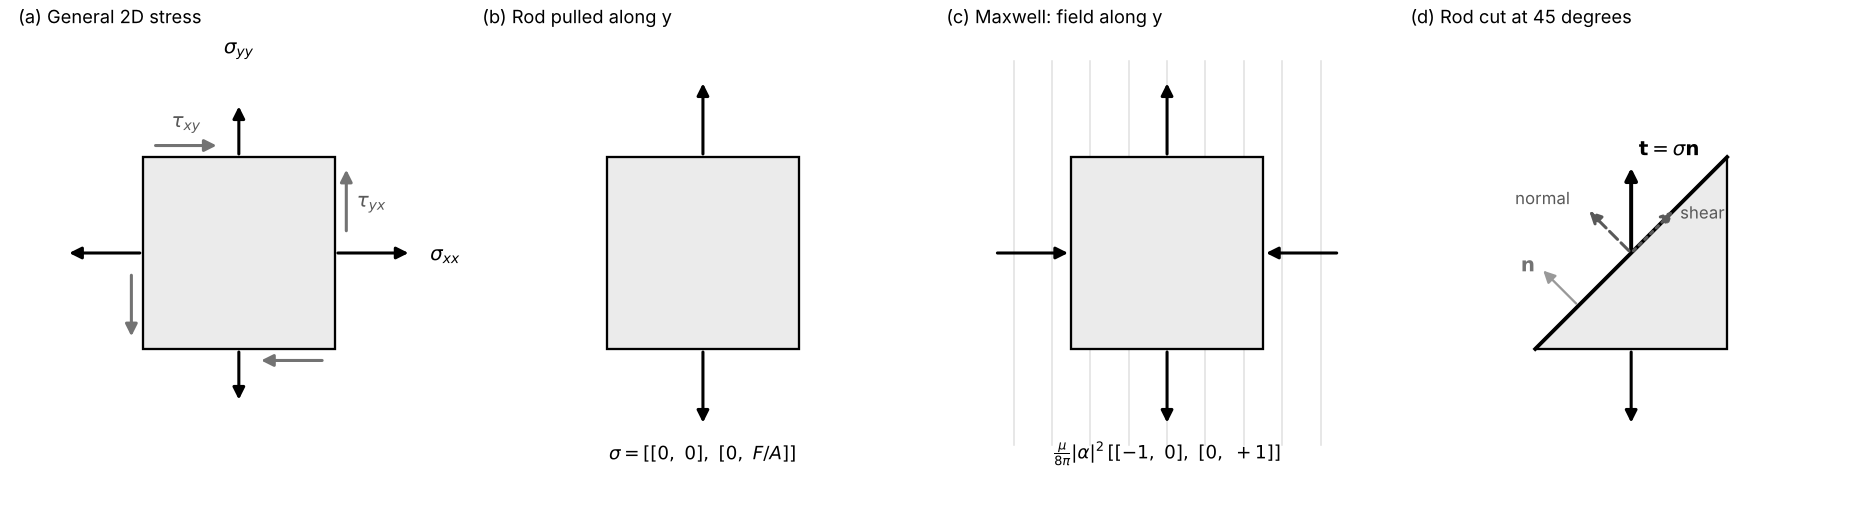

### Step 2. A stress that changes from place to place pushes the material

Stress is force per area, so the force on a face is **stress × face area**. Take a small square of size $dx \times dy$, one unit thick. Its right and left faces each have area $dy$. Its top and bottom faces each have area $dx$.

- Right face (normal $+\hat{\mathbf x}$): force $+\sigma_{xx}(x + dx)\,dy$ in the $x$ direction.
- Left face (normal $-\hat{\mathbf x}$): force $-\sigma_{xx}(x)\,dy$. Same stress table, but the face points the other way, so the force flips sign.
- Top and bottom faces: the shear $\sigma_{xy}$ adds forces $+\sigma_{xy}(y + dy)\,dx$ and $-\sigma_{xy}(y)\,dx$ in the $x$ direction.

Add the four. The net $x$ force on the square is

$$dF_x = \big[\sigma_{xx}(x+dx) - \sigma_{xx}(x)\big]dy + \big[\sigma_{xy}(y+dy) - \sigma_{xy}(y)\big]dx \;\approx\; \Big(\frac{\partial \sigma_{xx}}{\partial x} + \frac{\partial \sigma_{xy}}{\partial y}\Big)\,dx\,dy .$$

The product $dx\,dy = dA$ is the area of the square. So the net force is a number times $dA$:

$$dF_i = f_i\,dA, \qquad f_i = \partial_j\,\sigma_{ij}, \qquad \mathbf{f} = \nabla\cdot\sigma, \qquad\text{the divergence of the stress.}$$

$f_i$ is the force on the square per unit of its area. (In 3D the square becomes a box, $dA$ becomes the volume $dV = dx\,dy\,dz$, and $f_i$ is the force per unit volume.)

A uniform stress gives no force: opposite faces pull equally. Only a change in stress pushes. For a gas, $\sigma = -pI$ gives $\mathbf f = \nabla\cdot(-pI) = -\nabla p$: the gas pushes from high pressure to low. This is the pressure term of the Navier–Stokes equations.

**Course link: Theory of Elasticity. From the balance law to waves.** In Maxwell's medium the stress comes from the field $\boldsymbol\alpha$. In an elastic solid it comes from how much the material is stretched. The balance law is the same. Here it is, followed all the way to the wave equation.

**(i) Index form.** Let $u_i(\mathbf x, t)$ be the displacement of the material (how far each bit has moved from where it started). Add a body force $b_i$ per unit volume, such as weight. If the material is at rest, the forces balance:

$$\partial_j\sigma_{ij} + b_i = 0 \qquad (\text{equilibrium}).$$

If they do not balance, Newton's second law applies to each unit volume, with mass $\rho$ and acceleration $\ddot u_i = \partial^2 u_i/\partial t^2$:

$$\rho\,\ddot u_i = \partial_j\sigma_{ij} + b_i \qquad (\text{motion}).$$

**(ii) Vector form.** Each value of $i$ ($x$, $y$ or $z$) gives one equation. The term $\partial_j\sigma_{ij}$ is the $i$-th component of $\nabla\cdot\sigma$. So the three equations pack into

$$\nabla\cdot\sigma + \mathbf b = \mathbf 0 \quad (\text{equilibrium}), \qquad \rho\,\ddot{\mathbf u} = \nabla\cdot\sigma + \mathbf b \quad (\text{motion}).$$

**(iii) Waves in a rod (1D).** Go back to the rod and let it vibrate along its length. The strain is the stretch per unit length, $\varepsilon = \partial u/\partial x$. Hooke's law says the stress follows the strain: $\sigma = E\,\varepsilon = E\,\partial u/\partial x$, with $E$ the stiffness (Young's modulus). Drop the body force. The motion equation becomes

$$\rho\,\frac{\partial^2 u}{\partial t^2} = \frac{\partial}{\partial x}\Big(E\,\frac{\partial u}{\partial x}\Big) = E\,\frac{\partial^2 u}{\partial x^2} \quad\Longrightarrow\quad \frac{\partial^2 u}{\partial x^2} = \frac{1}{c^2}\,\frac{\partial^2 u}{\partial t^2}, \qquad c = \sqrt{E/\rho}.$$

This is the wave equation. The stiffness pushes, the density resists, and their ratio sets the speed. For steel, $E \approx 200$ GPa and $\rho \approx 7850$ kg/m³, so $c \approx 5000$ m/s.

**(iv) Waves in 3D.** For a solid that behaves the same in every direction, Hooke's law reads

$$\sigma_{ij} = \lambda\,\varepsilon_{kk}\,\delta_{ij} + 2G\,\varepsilon_{ij}, \qquad \varepsilon_{ij} = \tfrac12\big(\partial_i u_j + \partial_j u_i\big),$$

with $\lambda$ and $G$ the two Lamé constants. ($G$ is the shear stiffness. Books often call it $\mu$; this notebook saves $\mu$ for Maxwell.) The term $\lambda\,\varepsilon_{kk}\,\delta_{ij}$ is an equal push or pull on every face, set by $\varepsilon_{kk} = \varepsilon_{xx} + \varepsilon_{yy} + \varepsilon_{zz} = \nabla\cdot\mathbf u$, the change in volume. Take the divergence, term by term:

- $\partial_j\big(\lambda\,\varepsilon_{kk}\,\delta_{ij}\big) = \lambda\,\partial_i(\partial_k u_k) = \lambda\,\partial_i(\nabla\cdot\mathbf u)$. The $\delta_{ij}$ keeps only the term with $j = i$, so $\partial_j$ becomes $\partial_i$.
- $\partial_j\big(2G\,\varepsilon_{ij}\big) = G\,\big(\partial_i\partial_j u_j + \partial_j\partial_j u_i\big) = G\,\partial_i(\nabla\cdot\mathbf u) + G\,\nabla^2 u_i$.

So, with no body force,

$$\rho\,\ddot{\mathbf u} = (\lambda + G)\,\nabla(\nabla\cdot\mathbf u) + G\,\nabla^2\mathbf u \qquad (\text{the Navier–Cauchy equation}).$$

Two kinds of wave come out of it:

- **Shear (transverse) waves.** The material slides sideways without being squeezed, so $\nabla\cdot\mathbf u = 0$. Then $\nabla^2\mathbf u = \dfrac{1}{c_s^2}\,\ddot{\mathbf u}$, with $c_s = \sqrt{G/\rho}$.
- **Compression (longitudinal) waves.** The material is squeezed without turning, so $\nabla\times\mathbf u = 0$ and $\nabla(\nabla\cdot\mathbf u) = \nabla^2\mathbf u$. Then $\nabla^2\mathbf u = \dfrac{1}{c_p^2}\,\ddot{\mathbf u}$, with $c_p = \sqrt{(\lambda + 2G)/\rho}$.

**Why this matters for Maxwell.** In Part III, Maxwell treats light as a shear wave in his elastic medium. He computes its speed the same way as $c_s$: from the medium's shear stiffness and its density. Part 3 of this notebook builds the lattice version of that wave.

### Step 3. Maxwell's stress

**What $\boldsymbol\alpha$ is.** Maxwell names the magnetic force at a point by its three components, $\alpha$, $\beta$, $\gamma$. This notebook packs them into one arrow, $\boldsymbol\alpha = (\alpha, \beta, \gamma)$, and writes $\alpha_i$ for its $i$-th component. Its length is $|\boldsymbol\alpha| = \sqrt{\alpha^2 + \beta^2 + \gamma^2}$ (panel (b) below). In Maxwell's model the arrow has a mechanical meaning (panel (a)):

- its **direction** is the axis of the vortices at that point, which is also the direction of the line of force;
- its **length** $|\boldsymbol\alpha|$ is the speed of the vortex rims.

The coefficient $\mu$ is the density of the vortex medium. In today's notation, $\boldsymbol\alpha$ is the magnetic field $\mathbf H$, $\mu$ is the magnetic permeability, and $\mu\boldsymbol\alpha$ is the magnetic induction $\mathbf B$.

**The stress.** Maxwell finds (Prop. II) that the pressure across the lines of force exceeds the pressure along them by $\tfrac{\mu}{4\pi}|\boldsymbol\alpha|^2$. Here $\mu$ plays the density of the vortex medium and $|\boldsymbol\alpha|$ the speed of the vortex rims, so the excess is "density times speed squared", like the pressure in a spinning bucket. As a stress:

$$\sigma_{ij} = \underbrace{\frac{\mu}{4\pi}\,\alpha_i\alpha_j}_{\text{a rope along }\boldsymbol\alpha} \;-\; \underbrace{p_1\,\delta_{ij}}_{\text{a gas}} .$$

The schematic shows (a) what $\boldsymbol\alpha$ means for one vortex, (b) its three components $\alpha$, $\beta$, $\gamma$, (c) how a bundle of vortices pushes sideways and pulls along its length, and (d) how the two terms of the stress add up on a small square.

![Maxwell's vortices and stress: (a) one vortex, alpha along its axis with length equal to the rim speed; (b) the three components of alpha; (c) vortex tubes along the field push sideways and pull along their length; (d) rope term plus gas term equals Maxwell's stress.](attachment:maxwell_stress.png)
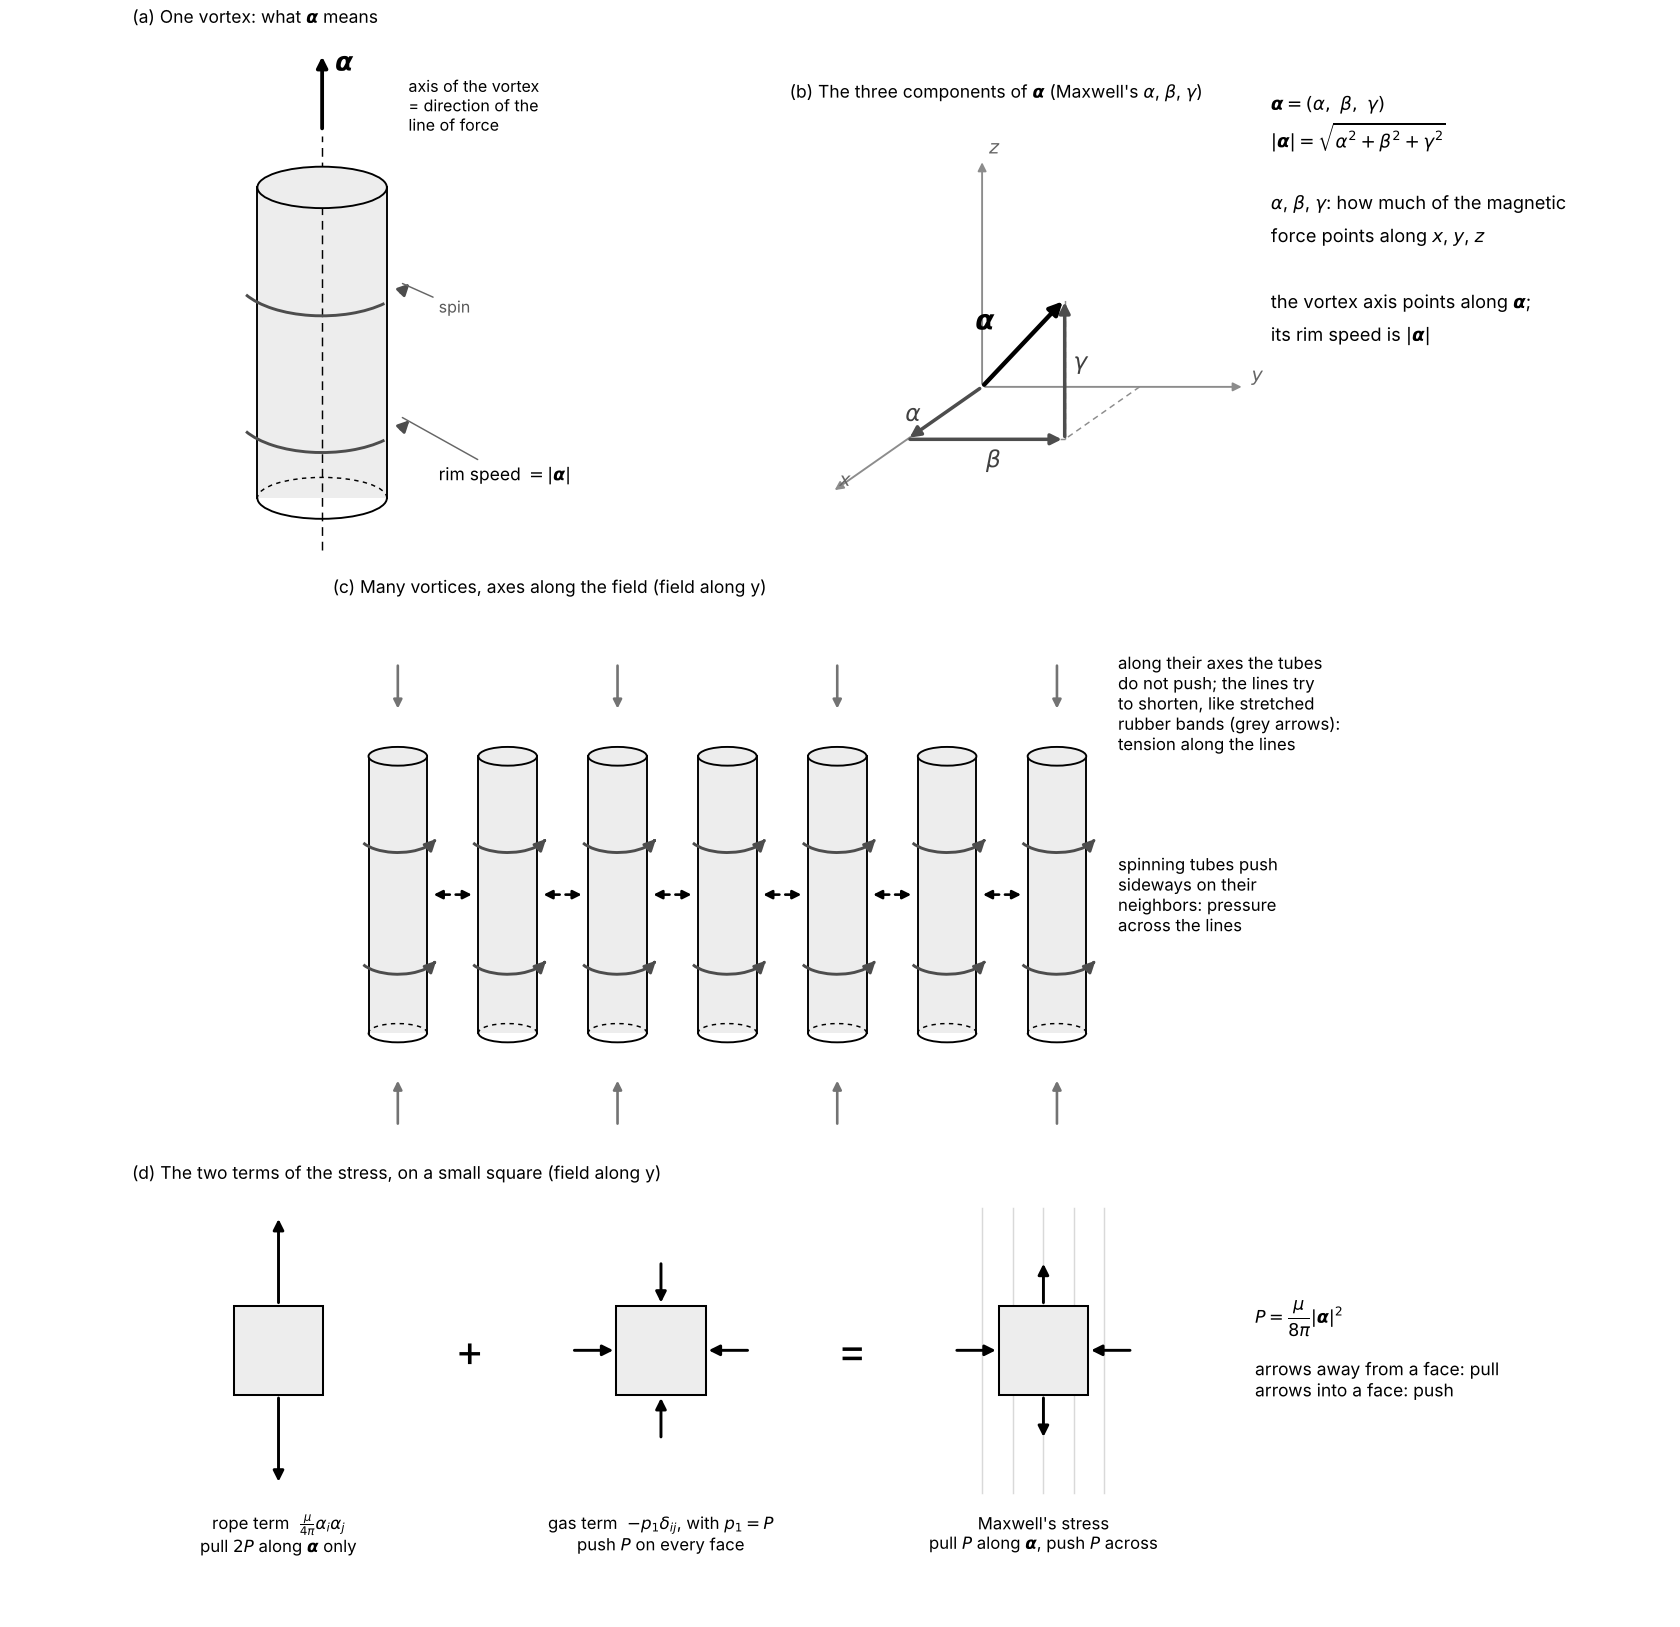

The first term is the rope of Step 1 with $\mathbf e = \boldsymbol\alpha/|\boldsymbol\alpha|$ and $T = \tfrac{\mu}{4\pi}|\boldsymbol\alpha|^2$. The second is a plain pressure $p_1$ in all directions. Maxwell leaves $p_1$ general. The choice $p_1 = \tfrac{\mu}{8\pi}|\boldsymbol\alpha|^2$ gives the modern **Maxwell stress**, and this notebook uses it. With it:

- along the lines of force: a **tension** $\tfrac{\mu}{8\pi}|\boldsymbol\alpha|^2$ (the lines try to shorten);
- across the lines: a **pressure** of the same size (the lines push each other apart).

That is Faraday's picture of lines of force, as rubber bands that pull along their length and push sideways. The cell below checks it: it computes the traction on cuts at several angles for a field along $x$.

In [2]:
def maxwell_stress(alpha, mu_over_4pi=1.0):
    alpha = np.asarray(alpha, float)
    return mu_over_4pi*(np.outer(alpha, alpha) - 0.5*(alpha @ alpha)*np.eye(2))

S = maxwell_stress([1.0, 0.0])                     # field along x, |alpha| = 1
print("stress table:\n", S)
for deg in (0, 45, 90):
    nvec = np.array([np.cos(np.radians(deg)), np.sin(np.radians(deg))])
    t = S @ nvec
    print(f"cut normal at {deg:2d} deg: traction = {t.round(3)},  normal part t.n = {t @ nvec:+.3f}  ({'tension' if t @ nvec > 1e-12 else 'pressure' if t @ nvec < -1e-12 else 'shear only'})")

stress table:
 [[ 0.5  0. ]
 [ 0.  -0.5]]
cut normal at  0 deg: traction = [0.5 0. ],  normal part t.n = +0.500  (tension)
cut normal at 45 deg: traction = [ 0.354 -0.354],  normal part t.n = +0.000  (shear only)
cut normal at 90 deg: traction = [ 0.  -0.5],  normal part t.n = -0.500  (pressure)


A cut across the field lines (normal at 0°) feels a pull of $+0.5$: tension. A cut along them (normal at 90°) feels a push of $-0.5$: pressure. At 45° the normal part vanishes and only shear is left.

### Step 3b. Where the rope term comes from (worked)

Maxwell's medium is a fluid, so look at one vortex tube of fluid with density $\rho$. Its axis points along the unit vector $\mathbf e$. It spins as a solid body: spin rate $\omega$, radius $R$, rim speed $v = \omega R$. The figure below follows the steps.

**(1) The fluid moves only around the axis.** At distance $r$ from the axis the speed is $\omega r$. It points across the axis, never along it (panel a).

**(2) Moving fluid carries a push.** Fluid with velocity $\mathbf u$ carries momentum $\rho\mathbf u$ per unit volume, and it carries that momentum along at speed $\mathbf u$. A cut through the fluid feels this flow of momentum as an extra push, the same push felt from a jet of water. In stress form:

$$\sigma_{ij} = -p\,\delta_{ij} - \rho\,u_i u_j .$$

**Course link: PDEs (Navier–Stokes).** The term $-\rho\,u_iu_j$ is the convection term $\rho(\mathbf u\cdot\nabla)\mathbf u$ of the Navier–Stokes equations, written as a stress. Averaged over turbulent eddies, the same term is called the Reynolds stress.

**(3) Average over the tube's cross-section.** Put the axis along $z$. The average of $r^2$ over the disk is

$$\langle r^2\rangle = \frac{1}{\pi R^2}\int_0^R r^2\,2\pi r\,dr = \frac{R^2}{2}, \qquad\text{so}\qquad \langle u_x^2 + u_y^2\rangle = \omega^2\langle r^2\rangle = \frac{v^2}{2}.$$

The disk looks the same from $x$ and from $y$, so the two share it equally: $\langle u_x^2\rangle = \langle u_y^2\rangle = v^2/4$. Along the axis, $\langle u_z^2\rangle = 0$. The cross term $\langle u_xu_y\rangle$ is zero, because opposite sides of the disk cancel (panel c).

**(4) The tube's average stress.** Let $\bar p$ be the average pressure. Then

$$\sigma_{xx} = \sigma_{yy} = -\bar p - \frac{\rho v^2}{4}, \qquad \sigma_{zz} = -\bar p, \qquad \text{all other entries } 0 .$$

Across the axis the medium is pushed harder, by $\rho v^2/4$. Along the axis it gets no extra push (panel b).

**(5) Split off the equal push.** Take the larger push, $p_1 = \bar p + \rho v^2/4$, as an equal push on every face. What is left acts on the $z$ faces only:

$$\sigma_{ij} = -p_1\,\delta_{ij} + \frac{\rho v^2}{4}\,e_ie_j .$$

Check the two directions. Across: $-p_1 + 0 = -\bar p - \rho v^2/4$. Along: $-p_1 + \rho v^2/4 = -\bar p$. Both match step (4). The second term has exactly the rope form $T\,e_ie_j$ of Step 1, with $T = \rho v^2/4$ (panel d).

**(6) Bring in $\boldsymbol\alpha$.** The arrow $\boldsymbol\alpha$ points along the axis and has the rim speed as its length, so $\boldsymbol\alpha = v\,\mathbf e$ and $\alpha_i\alpha_j = v^2 e_ie_j$:

$$\sigma_{ij} = \frac{\rho}{4}\,\alpha_i\alpha_j - p_1\,\delta_{ij} .$$

This is Maxwell's stress with $\mu/4\pi = \rho/4$, that is $\mu = \pi\rho$ for this tube. The factor $1/4$ comes from the solid-body spin: it depends on how the speed varies inside the vortex. Maxwell keeps that factor general and folds it, together with the density, into the single constant $\mu$. (Worth checking against Prop. II in the original paper.)

**What the rope term means.** Nothing in the medium pulls. Along the axis the push is smaller than across it, by $\rho v^2/4$. After an equal push on all faces is taken out, that shortfall looks exactly like a pull along the axis. This is why lines of force behave as if they "pull along their length".

**Try it 1.3.** Let every bit of fluid in the tube move at the same speed $v$ around the axis (instead of $\omega r$). Repeat steps (3)–(6). Show that the rope term becomes $\tfrac{\rho}{2}\alpha_i\alpha_j$, so $\mu = 2\pi\rho$. The form of the stress stays the same; only the constant changes.

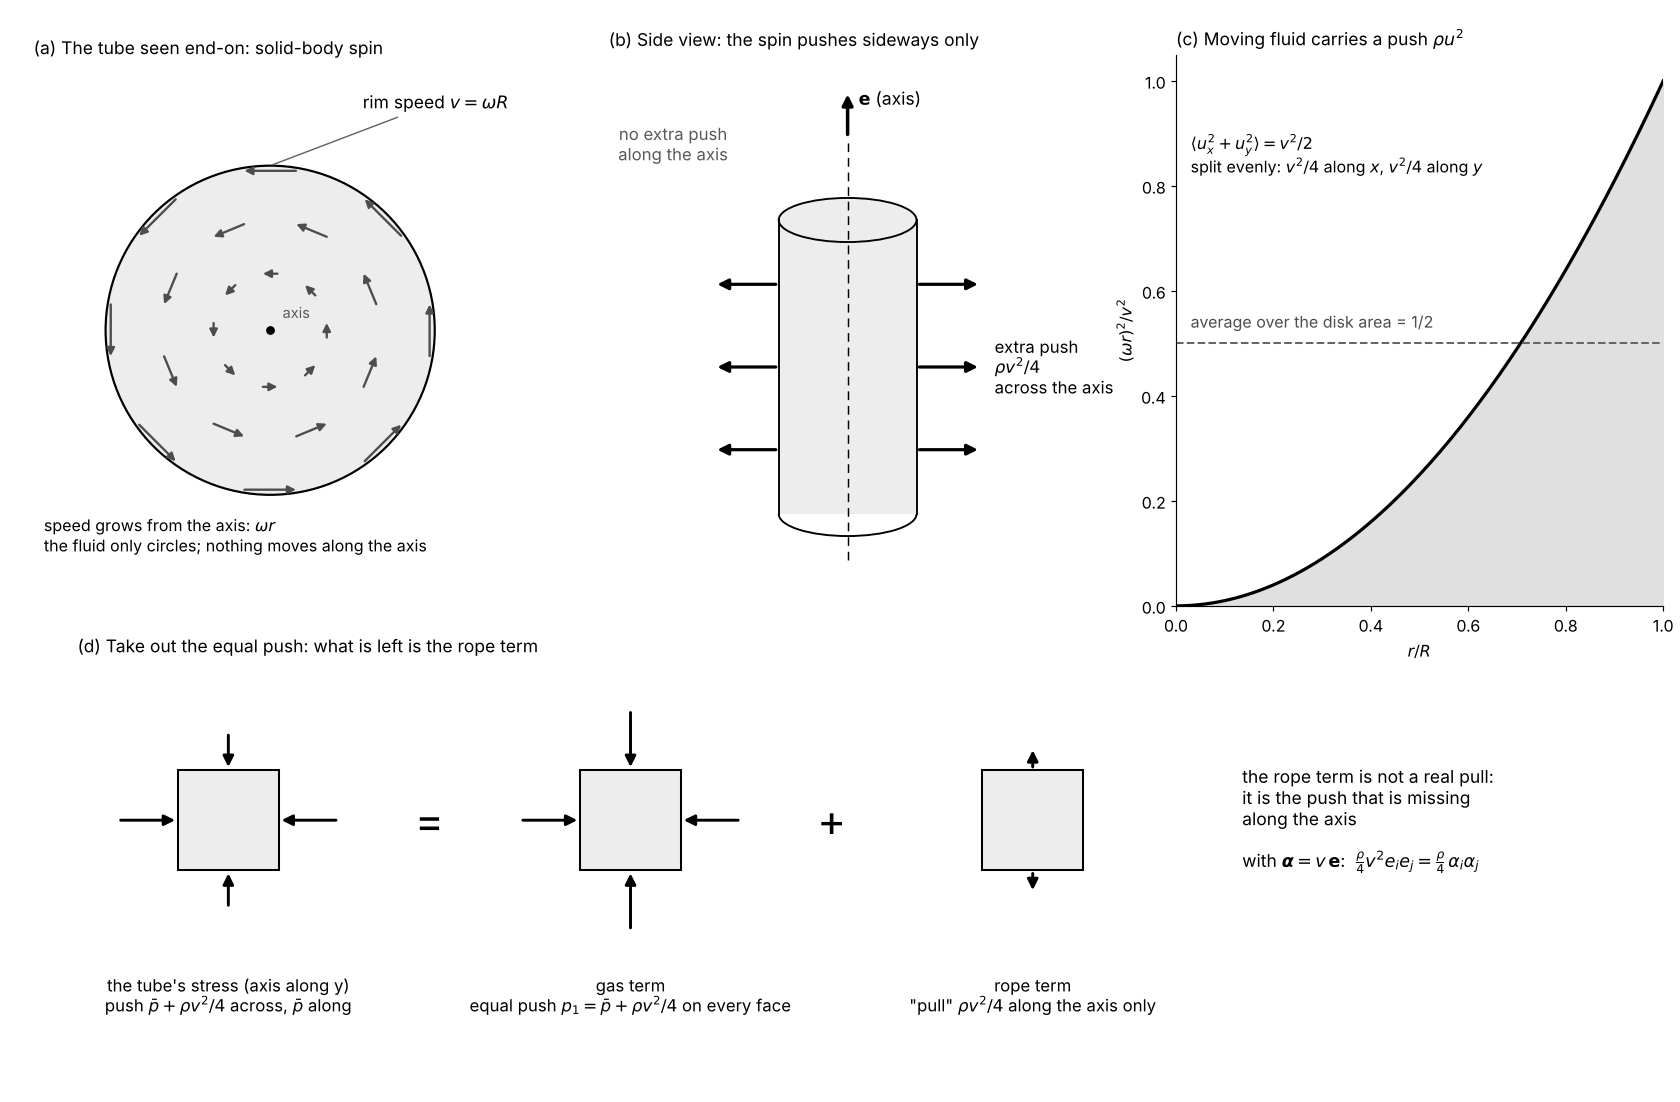

### Step 4. From the stress to the force

Apply Step 2 to Maxwell's stress:

$$f_i = \partial_j\sigma_{ij} = \frac{\mu}{4\pi}\,\partial_j(\alpha_i\alpha_j) \;-\; \partial_i p_1 .$$

**(a) Product rule** on the first term:

$$\partial_j(\alpha_i\alpha_j) = \alpha_i\,(\partial_j\alpha_j) + \alpha_j\,\partial_j\alpha_i = \alpha_i\,(\nabla\cdot\boldsymbol\alpha) + \big[(\boldsymbol\alpha\cdot\nabla)\boldsymbol\alpha\big]_i .$$

**(b) The pressure term.** With $p_1 = \tfrac{\mu}{8\pi}|\boldsymbol\alpha|^2$:

$$\partial_i p_1 = \frac{\mu}{4\pi}\,\alpha_j\,\partial_i\alpha_j = \frac{\mu}{4\pi}\Big[\nabla\big(\tfrac12|\boldsymbol\alpha|^2\big)\Big]_i .$$

**(c) A vector identity:**

$$\nabla\big(\tfrac12|\boldsymbol\alpha|^2\big) = (\boldsymbol\alpha\cdot\nabla)\boldsymbol\alpha + \boldsymbol\alpha\times(\nabla\times\boldsymbol\alpha).$$

Check it in 2D. Write $\boldsymbol\alpha = (a, b)$ and $\nabla\times\boldsymbol\alpha = \omega\,\hat{\mathbf z}$ with $\omega = \partial_x b - \partial_y a$. Then $\boldsymbol\alpha\times(\omega\hat{\mathbf z}) = (b\,\omega,\; -a\,\omega)$. The $x$ parts: left side $a\,\partial_x a + b\,\partial_x b$; first term on the right $a\,\partial_x a + b\,\partial_y a$. Their difference is $b(\partial_x b - \partial_y a) = b\,\omega$, which is the $x$ part of the last term.

**(d) Put (a), (b), (c) together.** The $(\boldsymbol\alpha\cdot\nabla)\boldsymbol\alpha$ terms cancel:

$$\boxed{\;\mathbf{f} = \frac{\mu}{4\pi}\Big[\boldsymbol{\alpha}\,(\nabla\cdot\boldsymbol{\alpha}) \;-\; \boldsymbol{\alpha}\times(\nabla\times\boldsymbol{\alpha})\Big]\;}$$

- The first term needs $\nabla\cdot\boldsymbol\alpha \neq 0$: a magnetic "pole". It pushes poles along the field.
- The second term needs $\nabla\times\boldsymbol\alpha \neq 0$. In Part II Maxwell shows that $\nabla\times\boldsymbol\alpha$ is the electric current. So this term is the force on a current. Since $-\boldsymbol\alpha\times\mathbf J = \mathbf J\times\boldsymbol\alpha$, it is the familiar $\mathbf J\times\mathbf B$.
- With a general $p_1$, one more term appears: $-\nabla\big(p_1 - \tfrac{\mu}{8\pi}|\boldsymbol\alpha|^2\big)$, an ordinary pressure gradient.

### Step 5. The wire, by hand

Let a round wire of radius $a$ carry a uniform current. Take $\mu/4\pi = 1$ and let $J$ stand for $\nabla\times\boldsymbol\alpha$ inside the wire.

**Inside** ($r < a$): $\boldsymbol\alpha = \tfrac{J}{2}(-y,\,x)$.

- $\nabla\cdot\boldsymbol\alpha = \partial_x(-\tfrac{J}{2}y) + \partial_y(\tfrac{J}{2}x) = 0$: no poles.
- $\omega = \partial_x(\tfrac{J}{2}x) - \partial_y(-\tfrac{J}{2}y) = J$.
- $\boldsymbol\alpha\times(J\hat{\mathbf z}) = (\alpha_y J,\; -\alpha_x J) = \tfrac{J^2}{2}(x,\; y)$.
- So $\mathbf f = -\tfrac{J^2}{2}(x,\; y)$: it points to the axis and grows with distance from it.

At $x = 0.5$ with $J = 1$: $f_x = -0.25$. The next code cell prints this number from the stress grid.

**Outside** ($r > a$): $\boldsymbol\alpha = \tfrac{Ja^2}{2}\,\dfrac{(-y,\,x)}{r^2}$.

- $\nabla\cdot\boldsymbol\alpha = 0$ again.
- $\omega = \tfrac{Ja^2}{2}\big[\partial_x(x/r^2) + \partial_y(y/r^2)\big] = \tfrac{Ja^2}{2}\,\dfrac{(r^2 - 2x^2) + (r^2 - 2y^2)}{r^4} = 0$.
- So $\mathbf f = 0$: outside the wire the tension along the circles and the pressure across them balance exactly.

The picture: the circular lines of force act like rubber bands around a bundle. Their tension squeezes the wire. This is the **pinch effect**.

**Check.** The cell below builds Maxwell's stress on a grid, takes its divergence numerically (Step 2), and compares with the boxed formula (Step 4).

largest error, divergence of stress vs formula: 0.00029
inside the wire the force points to the axis: f = -0.25 at x = 0.5


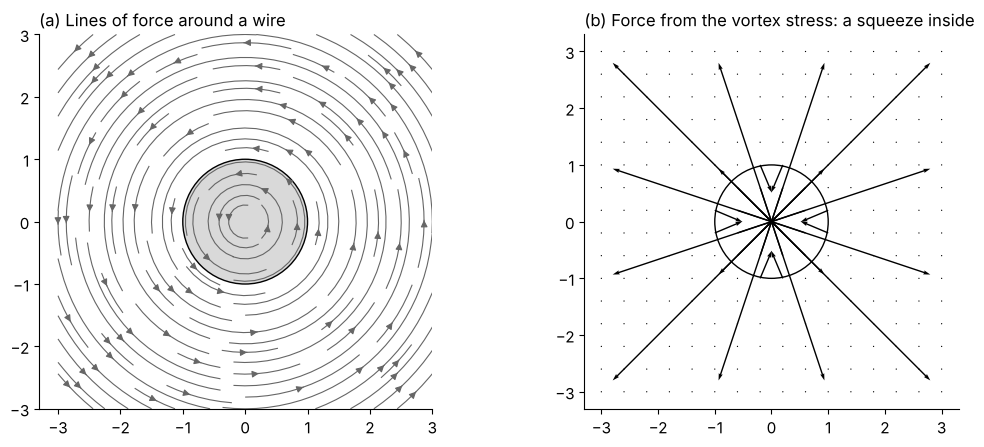

In [3]:
n, L = 241, 3.0
x = np.linspace(-L, L, n); h = x[1] - x[0]
X, Y = np.meshgrid(x, x, indexing="xy")          # arrays [iy, ix]
R2 = X**2 + Y**2
a, J = 1.0, 1.0                                    # wire radius, current density

def wire_field(H0=0.0):
    inside = R2 < a**2
    Hx = np.where(inside, -J/2*Y, -J*a**2/2*Y/np.maximum(R2, 1e-12)) + H0
    Hy = np.where(inside,  J/2*X,  J*a**2/2*X/np.maximum(R2, 1e-12))
    return Hx, Hy

def maxwell_force(Hx, Hy):
    p1 = 0.5*(Hx**2 + Hy**2)                       # mu H^2 / 8 pi with mu/4pi = 1
    sxx, sxy, syy = Hx*Hx - p1, Hx*Hy, Hy*Hy - p1
    d = lambda f: np.gradient(f, h)                 # returns (d/dy, d/dx)
    fx = d(sxx)[1] + d(sxy)[0]
    fy = d(sxy)[1] + d(syy)[0]
    return fx, fy

Hx, Hy = wire_field()
fx, fy = maxwell_force(Hx, Hy)
curl = np.gradient(Hy, h)[1] - np.gradient(Hx, h)[0]
fx_th, fy_th = -Hy*curl, Hx*curl                  # -alpha x (curl alpha), no poles here
ok = (np.sqrt(R2) < 0.85) | (np.sqrt(R2) > 1.15)  # skip the jump at the wire surface
print("largest error, divergence of stress vs formula:", np.abs(fx - fx_th)[ok].max().round(5))
print("inside the wire the force points to the axis: f =", (fx[n//2, n//2 + 20]).round(3), "at x =", x[n//2 + 20].round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
ax[0].streamplot(x, x, Hx, Hy, color="0.4", density=1.1, linewidth=0.8)
ax[0].add_patch(plt.Circle((0, 0), a, fc="0.85", ec="k"))
ax[0].set_title("(a) Lines of force around a wire"); ax[0].set_aspect("equal")
s = slice(None, None, 16)
ax[1].quiver(X[s, s], Y[s, s], fx[s, s], fy[s, s], color="k")
ax[1].add_patch(plt.Circle((0, 0), a, fc="none", ec="k"))
ax[1].set_title("(b) Force from the vortex stress: a squeeze inside"); ax[1].set_aspect("equal")
plt.tight_layout(); plt.show()

Inside the wire the force points toward the axis. The tension along the circular lines of force squeezes the wire (the "pinch effect"). Outside the wire the force is zero: there the pressure and the tension balance.

**Try it 1.1.** Add a uniform field $H_0$ along $x$ with `wire_field(H0=0.5)`. Integrate $f_y$ over the wire's disk with `(fy*(R2 < a**2)).sum()*h*h`. Compare with $J\,\pi a^2 H_0$. This is the force on a wire in a magnet, obtained from stresses alone. *Hint:* by Step 4, $\mathbf f = -\boldsymbol\alpha\times(J\hat{\mathbf z})$ inside. The wire's own field gives zero net force by symmetry. The added field gives $-(H_0\hat{\mathbf x})\times(J\hat{\mathbf z}) = H_0 J\,\hat{\mathbf y}$ at every point of the disk. The grid answer comes within about 1%, because the grid's disk is not quite round.

**Try it 1.2.** Show that a uniform field gives no force anywhere. Which term of the identity vanishes, and why?

---
## Part 2. Idle wheels and electric current (1861, Part II)

**The problem.** Two neighboring vortices that spin the same way have touching surfaces that move in opposite directions. They would grind. Maxwell fixes this with a layer of small particles between the vortices, like idle wheels in a machine. Each particle rolls between two vortices and moves at the **mean** of the two surface speeds.

**The result.** Where all vortices spin at the same rate, the two surface speeds cancel and the particles stay still. Where the spin changes from place to place, the particles drift. Maxwell identifies that drift as the electric current, proportional to $\nabla\times\boldsymbol{\alpha}$ (Prop. V).

**On a lattice.** Take square cells of radius $R$ on spacing 1, with spin $\Omega_{ij}$ (counterclockwise positive). At the contact between a left cell $i$ and a right cell $i+1$, the left rim moves up at $\Omega_i R$ and the right rim moves down at $\Omega_{i+1} R$. The particle there moves up at

$$v_y = \tfrac{R}{2}\,(\Omega_i - \Omega_{i+1}) \;\approx\; -\tfrac{R}{2}\,\partial_x \Omega .$$

The same rule on horizontal contacts gives $v_x \approx \tfrac{R}{2}\partial_y\Omega$. Together $\mathbf{v} = \tfrac{R}{2}\nabla\times(\Omega\,\hat{\mathbf{z}})$: a discrete curl. In experiment 9 the fluid in the gaps between the vibrating shells plays these particles.

**Course link: Discrete Mathematical Modeling, PDEs.** The idle-wheel rule is a finite-difference curl. Summing it along a line telescopes, which is a discrete Stokes theorem.

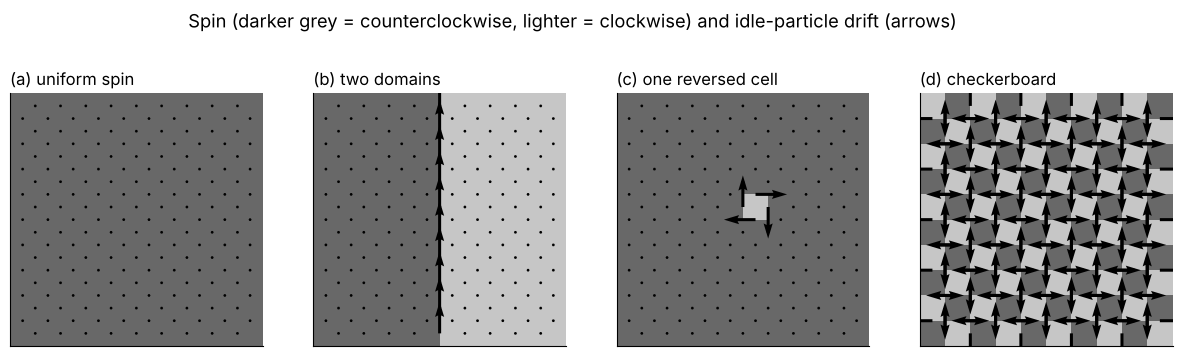

Total drift across row j=3: 0.5   (R/2)(spin at left end - spin at right end): 0.5


In [4]:
def idle_particles(Om, R=0.5):
    # Om[i, j]: i = x index, j = y index
    vy = 0.5*R*(Om[:-1, :] - Om[1:, :])     # vertical contacts, between (i,j) and (i+1,j)
    vx = 0.5*R*(Om[:, 1:] - Om[:, :-1])     # horizontal contacts, between (i,j) and (i,j+1)
    return vx, vy

N = 10
I_, J_ = np.meshgrid(np.arange(N), np.arange(N), indexing="ij")
patterns = {
    "(a) uniform spin": np.ones((N, N)),
    "(b) two domains": np.where(I_ < N//2, 1.0, -1.0),
    "(c) one reversed cell": np.where((I_ == N//2) & (J_ == N//2), -1.0, 1.0),
    "(d) checkerboard": np.where((I_ + J_) % 2 == 0, 1.0, -1.0),
}
fig, axs = plt.subplots(1, 4, figsize=(15, 4))
for ax, (name, Om) in zip(axs, patterns.items()):
    vx, vy = idle_particles(Om)
    ax.imshow(Om.T, origin="lower", cmap="Greys", vmin=-3, vmax=3, extent=(-0.5, N-0.5, -0.5, N-0.5))
    xi, yj = np.meshgrid(np.arange(N-1) + 0.5, np.arange(N), indexing="ij")
    ax.quiver(xi, yj, 0*vy, vy, scale=4, color="k", width=0.012)
    xi, yj = np.meshgrid(np.arange(N), np.arange(N-1) + 0.5, indexing="ij")
    ax.quiver(xi, yj, vx, 0*vx, scale=4, color="k", width=0.012)
    ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Spin (darker grey = counterclockwise, lighter = clockwise) and idle-particle drift (arrows)", y=1.02)
plt.show()

Om = patterns["(b) two domains"]
vx, vy = idle_particles(Om)
print("Total drift across row j=3:", vy[:, 3].sum(), "  (R/2)(spin at left end - spin at right end):", 0.5*0.5*(Om[0, 3] - Om[-1, 3]))

The four panels reproduce what experiment 9 found with real vibrating shells: no current for uniform spin, current sheets at domain walls, a ring around a reversed cell, and a loop around every cell of a checkerboard.

**Try it 2.1.** Show by hand that the sum of $v_y$ along a row equals $\tfrac{R}{2}(\Omega_{\text{first}} - \Omega_{\text{last}})$ for any spin pattern. The printed line checks one case.

**Try it 2.2.** Use a smooth spin pattern, `Om = np.exp(-((I_-4.5)**2 + (J_-4.5)**2)/8)`. Compare the drift with $\tfrac{R}{2}\nabla\times(\Omega\hat{\mathbf z})$ computed by `np.gradient`. How does the error shrink with a finer lattice?

**Note from the experiments.** In experiment 9 the fluid "idle particles" did not follow a single constant: the best fit of current to $\nabla\times$spin missed by 33%. Maxwell's rolling particles give an exact local law. A viscous fluid spreads the coupling over many cells.

---
## Part 3. Elastic cells and the speed of light (1861–62, Part III)

**Maxwell's step.** In Part III Maxwell makes the cells elastic. A cell that is twisted springs back. Twist then passes from cell to cell as a wave. Maxwell computed the wave speed from the elastic constants and from electrical measurements. He reported a speed of about 310,740,000 m/s and compared it with Fizeau's measured speed of light, about 314,858,000 m/s. His conclusion: light is a wave in the same medium that carries electric and magnetic effects.

**The lattice (option A, experiment 11).** Give each cell a moment of inertia $I$. Put a spring of stiffness $k$ in each idle particle. In one dimension:

$$I\,\dot\Omega_n = \tfrac{R}{2}\big(F_{n-\frac12} - F_{n+\frac12}\big), \qquad \dot F_{n+\frac12} = k\,\tfrac{R}{2}\big(\Omega_n - \Omega_{n+1}\big).$$

Here $F$ is the spring pull at a contact. Eliminate $F$:

$$\ddot\Omega_n = c^2\big(\Omega_{n+1} - 2\Omega_n + \Omega_{n-1}\big), \qquad c = \tfrac{R}{2}\sqrt{k/I}.$$

This is the wave equation on a lattice. Spin plays $H$, the spring pull plays $E$, $\mu = 2I/R$ and $1/\varepsilon = kR/2$. With $I=1$, $k=16$, $R=0.5$, the speed is $c = 1$.

**Course link: PDEs, Advanced Numerical Analysis.** Updating $F$ and $\Omega$ half a step apart is the leapfrog scheme. In 2D it is exactly the Yee scheme used for Maxwell's equations in computational electromagnetics.

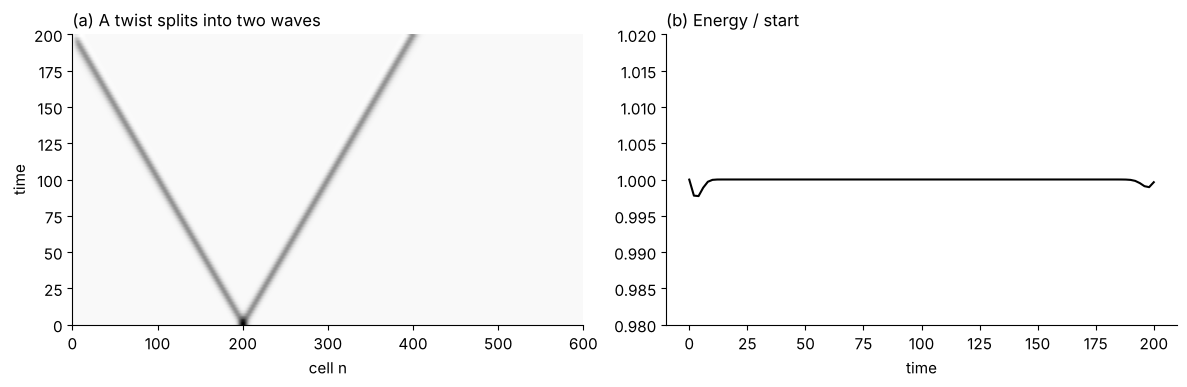

theory c = 1.000;  fitted speed = 0.9891 +/- 0.0008 (std. error)


In [5]:
def chain_run(N=600, I=1.0, k=16.0, R=0.5, dt=0.05, T=200.0, every=40, tc=np.inf):
    c = R/2*np.sqrt(k/I)
    n = np.arange(N)
    Om = np.exp(-((n - N/3)/6.0)**2)            # a twist pulse
    F = np.zeros(N - 1)
    out_t, out_Om, out_E = [], [], []
    for s in range(int(T/dt) + 1):
        if s % every == 0:
            out_t.append(s*dt); out_Om.append(Om.copy())
            out_E.append(0.5*I*(Om**2).sum() + 0.5*(F**2).sum()/k)
        F = (F*(1 - dt/(2*tc)) + dt*k*R/2*(Om[:-1] - Om[1:]))/(1 + dt/(2*tc))   # slip: a conductor
        Om[1:-1] += dt/I*R/2*(F[:-1] - F[1:])
    return c, np.array(out_t), np.array(out_Om), np.array(out_E)

c, t, Om, E = chain_run()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(Om, aspect="auto", origin="lower", extent=(0, Om.shape[1], 0, t[-1]), cmap="Greys")
ax[0].set_xlabel("cell n"); ax[0].set_ylabel("time"); ax[0].set_title("(a) A twist splits into two waves")
ax[1].plot(t, E/E[0]); ax[1].set_ylim(0.98, 1.02); ax[1].set_xlabel("time"); ax[1].set_title("(b) Energy / start")
plt.tight_layout(); plt.show()

# measure the speed: peak of the right-going half, then a straight-line fit
right = np.array([np.argmax(o[200:]) + 200 for o in Om])
use = (t > 10) & (t < 150)
fit = stats.linregress(t[use], right[use])
print(f"theory c = {c:.3f};  fitted speed = {fit.slope:.4f} +/- {fit.stderr:.4f} (std. error)")

**Course link: Linear Statistical Models.** The speed comes from a least-squares line through (time, peak position). Look at the result closely: the fitted speed misses $c = 1$ by more than ten standard errors. The standard error assumes independent noise around the line. Here the residuals are not noise. The peak sits on whole cells, so its position moves in steps. The pulse also spreads a little, because short waves travel slower than $c$ on a lattice (next cell). A small standard error does not mean a correct model.

**Try it 3.0.** Replace the peak by the centroid of the right-going half, `(o[200:]*np.arange(200, len(o))).sum()/o[200:].sum()`, and refit. Plot the residuals in both cases.

**Dispersion from a matrix.** Write the lattice as $\ddot{\boldsymbol\Omega} = -c^2 A\,\boldsymbol\Omega$, with $A$ the periodic second-difference matrix. Its eigenvalues give the frequencies: $\omega_m = 2c\,\sin(\pi m/N)$. Long waves travel at $c$; short waves are slower. That is lattice dispersion.

**Course link: Numerical Matrix Analysis.** $A$ is circulant. Every circulant matrix is diagonalized by the discrete Fourier transform, so its eigenvectors are sines and cosines.

largest gap, matrix eigenvalues vs 2c sin(k/2): 0.0


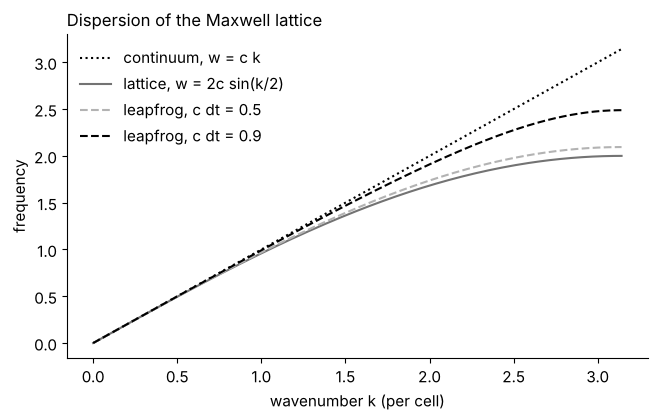

In [6]:
N = 64
A = linalg.circulant(np.r_[2, -1, np.zeros(N - 3), -1])
w_num = np.sqrt(np.clip(np.linalg.eigvalsh(A), 0, None))*c
kk = 2*np.pi*np.arange(N)/N
w_th = np.sort(2*c*np.abs(np.sin(kk/2)))
print("largest gap, matrix eigenvalues vs 2c sin(k/2):", np.abs(np.sort(w_num) - w_th).max().round(12))

k = np.linspace(0, np.pi, 200)
plt.plot(k, c*k, ":", label="continuum, w = c k")
plt.plot(k, 2*c*np.sin(k/2), label="lattice, w = 2c sin(k/2)")
for cdt in (0.5, 0.9):
    plt.plot(k, 2*c/cdt*np.arcsin(cdt*np.sin(k/2)), "--", label=f"leapfrog, c dt = {cdt}")
plt.xlabel("wavenumber k (per cell)"); plt.ylabel("frequency"); plt.legend(frameon=False); plt.title("Dispersion of the Maxwell lattice")
plt.show()

The leapfrog curves follow $\sin(\omega\,dt/2) = c\,dt\,\sin(k/2)$. Time stepping adds its own dispersion. At $c\,dt = 1$ (the "magic time step") the 1D scheme is exact.

**Try it 3.1 (stability).** Run `chain_run(dt=1.05, T=60, every=1)` so that $c\,dt > 1$. Watch the energy. Then derive the Courant limit $c\,dt \le 1$ by a von Neumann analysis: put $\Omega_n \propto g^s e^{ikn}$ and ask when $|g| \le 1$.

**Try it 3.2 (a conductor).** Let the idle particles slip: `chain_run(tc=1.5)`. The slip time $t_c$ acts as a conductivity $\sigma = \varepsilon/t_c$. Drive one end at frequency $\omega$ and measure how fast the wave decays. Compare with the skin depth $\delta = \sqrt{2/(\mu\sigma\omega)}$ when $\sigma \gg \varepsilon\omega$. Experiment 11 found 3.40 cells against 3.43 from theory.

---
## Part 4. Vibrating shells in an ideal fluid (experiment 12)

Now replace Maxwell's rigid wheels with the shells of this project. Each shell vibrates in two **oval modes**, $r = R + a\cos 2\theta + b\sin 2\theta$. The fluid has no viscosity and starts at rest, so it never swirls (Kelvin's theorem) and its flow has a potential: $\mathbf{u} = \nabla\phi$ with $\nabla^2\phi = 0$.

**One shell.** The wall moves out at speed $\dot a\cos 2\theta$. Outside, the potential that matches it and dies away is $\phi = -\tfrac{\dot a R^3}{2r^2}\cos 2\theta$. Inside it is $\phi = \tfrac{\dot a\, r^2}{2R}\cos 2\theta$. The fluid's kinetic energy is $\tfrac12 m\,\dot a^2$, which defines the **added mass** $m$.

**Course link: PDEs.** These are separation-of-variables solutions of Laplace's equation, $r^{\pm m}\cos m\theta$.

In [7]:
R, rho = 0.45, 1.0
# outside: |grad phi|^2 = R^6 / r^6 for adot = 1 ; inside: r^2 / R^2
ke_out = 0.5*rho*integrate.quad(lambda r: 2*np.pi*r*R**6/r**6, R, np.inf)[0]
ke_in = 0.5*rho*integrate.quad(lambda r: 2*np.pi*r*r**2/R**2, 0, R)[0]
print(f"added mass outside: {2*ke_out:.5f}   theory pi rho R^2 / 2 = {np.pi*rho*R**2/2:.5f}")
print(f"added mass inside:  {2*ke_in:.5f}   (same)")

added mass outside: 0.31809   theory pi rho R^2 / 2 = 0.31809
added mass inside:  0.31809   (same)


**Two shells.** A vibrating shell sends out a field $\propto r^{-2}\cos 2\theta$. A neighbor at distance $d$ sees part of it as its own oval mode. The neighbor's wall cannot move through the fluid, so it reflects that part back, which doubles it. The leading coupling is a shared mass

$$m_1 \approx \frac{3\pi\rho R^6}{d^4} \quad (\text{oval axes along the line of centers}),$$

and the opposite sign for ovals at 45°. Experiment 12 computed it exactly with multipoles: $m_1 = 0.0915$ for $R = 0.45$, $d = 1$, against $0.078$ at leading order. Inside a lattice the self mass grows to $m_0 = 0.911$.

**A chain.** In a row of shells the equations are $M\ddot{\mathbf q} + K\mathbf q = 0$ with $M = m_0 I + m_1(S + S^{T})$, where $S$ shifts by one cell. The shells share **mass**, not springs. Any matrix that commutes with $S$ has eigenvectors $e^{ikn}$, so

$$\omega(k) = \sqrt{\frac{K}{m_0 + 2m_1\cos k}} .$$

**Course link: Modern Algebra.** The lattice translations form a cyclic group $\mathbb{Z}_N$. Its characters are $e^{2\pi i m n/N}$. $M$ and $K$ commute with every translation, so the characters diagonalize them both (Bloch's theorem). On the hexagonal lattice the six-fold rotations add more structure: the two oval modes behave like a spin-2 object.

oval along the chain (a): band 0.913 to 1.119; largest gap vs Bloch formula 6.7e-16
oval at 45 degrees (b): band 0.913 to 1.119; largest gap vs Bloch formula 6.7e-16


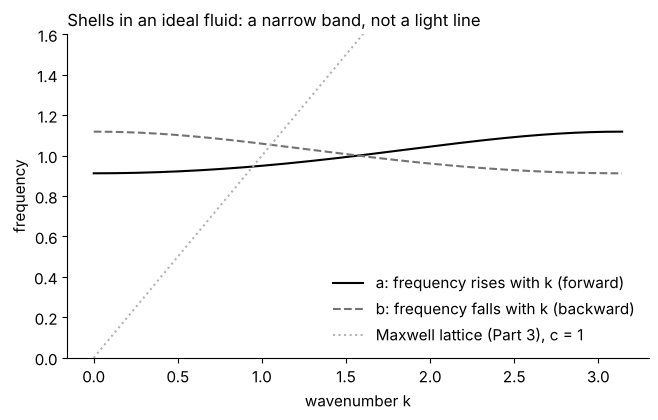

In [8]:
m0, K = 0.911, 0.911          # K chosen so a shell alone in its cage rings at 1
Nc = 48
for m1, name in ((+0.0915, "oval along the chain (a)"), (-0.0915, "oval at 45 degrees (b)")):
    M = linalg.circulant(np.r_[m0, m1, np.zeros(Nc - 3), m1])
    w = np.sqrt(linalg.eigh(K*np.eye(Nc), M, eigvals_only=True))
    kk = 2*np.pi*np.arange(Nc)/Nc
    w_th = np.sqrt(K/(m0 + 2*m1*np.cos(kk)))
    print(f"{name}: band {w.min():.3f} to {w.max():.3f}; largest gap vs Bloch formula {np.abs(np.sort(w) - np.sort(w_th)).max():.1e}")

k = np.linspace(0, np.pi, 200)
plt.plot(k, np.sqrt(K/(m0 + 2*0.0915*np.cos(k))), label="a: frequency rises with k (forward)")
plt.plot(k, np.sqrt(K/(m0 - 2*0.0915*np.cos(k))), "--", label="b: frequency falls with k (backward)")
plt.plot(k, k, ":", label="Maxwell lattice (Part 3), c = 1")
plt.ylim(0, 1.6); plt.xlabel("wavenumber k"); plt.ylabel("frequency"); plt.legend(frameon=False)
plt.title("Shells in an ideal fluid: a narrow band, not a light line"); plt.show()

Two lessons from this plot, both seen in experiment 12:

1. **A band, not a light line.** Shared mass shifts the frequency a little around 1. Long waves do not travel at a finite speed. Light needs a spring between neighbors (Part 3); an incompressible fluid supplies only mass.
2. **Backward waves.** On the b band the frequency falls as $k$ grows. The group velocity $d\omega/dk$ then points against the phase velocity $\omega/k$. Crests move one way; the energy moves the other. The run below shows it.

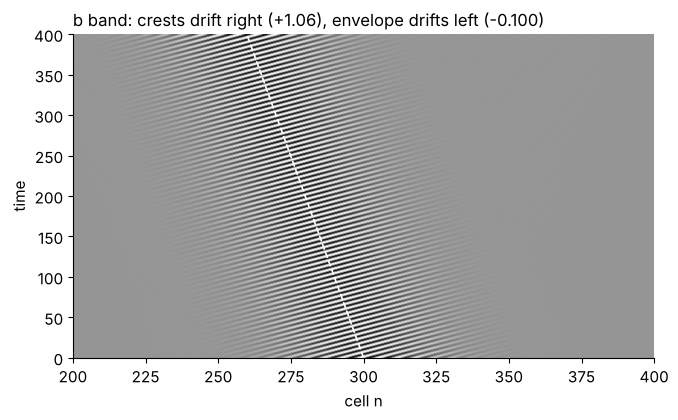

In [9]:
Nc, m1 = 600, -0.0915
M = linalg.circulant(np.r_[m0, m1, np.zeros(Nc - 3), m1]); Minv = np.linalg.inv(M)
k0 = 1.0
w0 = np.sqrt(K/(m0 + 2*m1*np.cos(k0)))
vg = -0.5*w0**3/K*(-2*m1*np.sin(k0))          # d omega / dk
n = np.arange(Nc); env = np.exp(-((n - Nc/2)/25.0)**2)
q, v = env*np.cos(k0*n), env*w0*np.sin(k0*n)   # crests moving to +n
dt, T = 0.1, 400.0
acc = -K*(Minv @ q); rows = []
for s in range(int(T/dt)):
    v += 0.5*dt*acc; q += dt*v; acc = -K*(Minv @ q); v += 0.5*dt*acc
    if s % 10 == 0: rows.append(q.copy())
rows = np.array(rows)
plt.imshow(rows[:, 200:400], aspect="auto", origin="lower", extent=(200, 400, 0, T), cmap="Greys")
plt.plot(Nc/2 + vg*np.linspace(0, T, 50), np.linspace(0, T, 50), "w--", lw=1.2)
plt.xlabel("cell n"); plt.ylabel("time")
plt.title(f"b band: crests drift right (+{w0/k0:.2f}), envelope drifts left ({vg:.3f})"); plt.show()

The stripes (crests) tilt to the right. The bright region (the packet) slides to the left along the dashed line $n = n_0 + v_g t$. Experiment 12's movie at drive 1.05 showed the same thing in 2D.

**Try it 4.1.** Set `m1 = +0.0915` (the a band). Do crests and envelope now move the same way?

**Try it 4.2.** Prove that $M$ and $S$ commute, and that this forces the eigenvectors of $M^{-1}K$ to be $e^{ikn}$ when the eigenvalues are distinct. Where does the argument fail at $k$ and $-k$?

---
## Part 5. A four-lobed tension pattern (experiment 13)

Let the shell tension vary around the shell, $T(\theta) = 1 + \delta\cos 4\theta$. Model the shell's stored energy like a string bent around a circle:

$$U = \frac{1}{2}\oint T(\theta)\,\big(\eta'^2 - \eta^2\big)\,d\theta ,$$

where $\eta(\theta)$ is the wall displacement. Put in $\eta = a\cos 2\theta$ or $\eta = b\sin 2\theta$ and integrate. The result: oval a gets stiffness $K(1 - \tfrac56\delta)$ and oval b gets $K(1 + \tfrac56\delta)$. The tension slope is zero every 45°, so the lobes and the nodes of both ovals sit at those points and stay there. The wall bends most sharply at the nodes, so the tension at the nodes sets the stiffness.

**Course link: Theory of Elasticity, Mathematical Modeling.** This is the Rayleigh–Ritz method: guess the shape, compute the energy, read off the stiffness.

In [10]:
th = np.linspace(0, 2*np.pi, 4001)[:-1]; dth = th[1] - th[0]
def stiffness(eta, deta, delta, pattern=4):
    T = 1 + delta*np.cos(pattern*th)
    return (T*(deta**2 - eta**2)).sum()*dth
for delta in (0.0, 0.12, 0.24):
    Ka = stiffness(np.cos(2*th), -2*np.sin(2*th), delta)
    Kb = stiffness(np.sin(2*th), 2*np.cos(2*th), delta)
    Kab = (((1 + delta*np.cos(4*th))*((-2*np.sin(2*th))*(2*np.cos(2*th)) - np.cos(2*th)*np.sin(2*th))).sum()*dth)
    K0 = stiffness(np.cos(2*th), -2*np.sin(2*th), 0.0)
    print(f"delta = {delta:.2f}: K_a/K0 = {Ka/K0:.4f} (theory {1 - 5*delta/6:.4f}),  K_b/K0 = {Kb/K0:.4f} (theory {1 + 5*delta/6:.4f}),  cross term {Kab:.1e}")

delta = 0.00: K_a/K0 = 1.0000 (theory 1.0000),  K_b/K0 = 1.0000 (theory 1.0000),  cross term 1.8e-16
delta = 0.12: K_a/K0 = 0.9000 (theory 0.9000),  K_b/K0 = 1.1000 (theory 1.1000),  cross term 0.0e+00
delta = 0.24: K_a/K0 = 0.8000 (theory 0.8000),  K_b/K0 = 1.2000 (theory 1.2000),  cross term 0.0e+00


**Try it 5.1.** Use a two-lobed pattern, `pattern=2`. Show that a and b keep equal stiffness. Then show that the pattern now couples the oval to the four-lobed shape $\cos 4\theta$: compute the cross term between $\cos 2\theta$ and $\cos 4\theta$.

**Try it 5.2.** In a lattice the split $K(1\mp\varepsilon)$ moves the two bands apart (experiment 13: at long waves, 1.005 and 1.23). Add it to the chain of Part 4 with `K_a = K*(1-0.2)` and `K_b = K*(1+0.2)` and plot both bands.

---
## Part 6. Nonlinear shells: Duffing, chaos and breathers

So far every model is linear. Real shells stiffen when stretched far, as a guitar string does. Each oval mode then obeys a **Duffing** equation,

$$\ddot x + \omega_0^2 x + \beta x^3 = 0 .$$

**Course link: Continuous Dynamical Systems and Chaos.** A Lindstedt–Poincaré expansion gives the frequency shift $\omega \approx \omega_0 + \tfrac{3\beta A^2}{8\omega_0}$ for amplitude $A$. A stiffening shell rings faster at large amplitude.

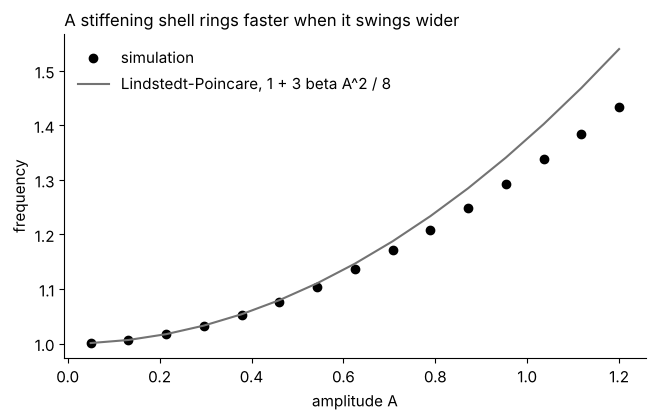

In [11]:
def duffing_period(A, beta, w0=1.0):
    sol = integrate.solve_ivp(lambda t, y: [y[1], -w0**2*y[0] - beta*y[0]**3], (0, 60), [A, 0],
                              rtol=1e-10, atol=1e-12, dense_output=True, max_step=0.05)
    tt = np.linspace(0, 60, 60001); x = sol.sol(tt)[0]
    up = np.nonzero((x[:-1] < 0) & (x[1:] >= 0))[0]
    return (tt[up[-1]] - tt[up[0]])/(len(up) - 1)
beta = 1.0
As = np.linspace(0.05, 1.2, 15)
w_meas = np.array([2*np.pi/duffing_period(A, beta) for A in As])
plt.plot(As, w_meas, "o", label="simulation")
plt.plot(As, 1 + 3*beta*As**2/8, label="Lindstedt-Poincare, 1 + 3 beta A^2 / 8")
plt.xlabel("amplitude A"); plt.ylabel("frequency"); plt.legend(frameon=False); plt.title("A stiffening shell rings faster when it swings wider"); plt.show()

**Driven, damped, and chaotic.** A shell squeezed hard enough buckles: it has two stable bent shapes. Its mode then obeys the double-well Duffing equation $\ddot x + \gamma\dot x - x + x^3 = F\cos\omega t$. Sample the motion once per drive period. That defines a map, the **Poincaré map**.

**Course link: Discrete Dynamical Systems and Chaos.** The Poincaré map turns a flow into a discrete system. The bifurcation diagram below shows period doubling and chaos as the drive grows.

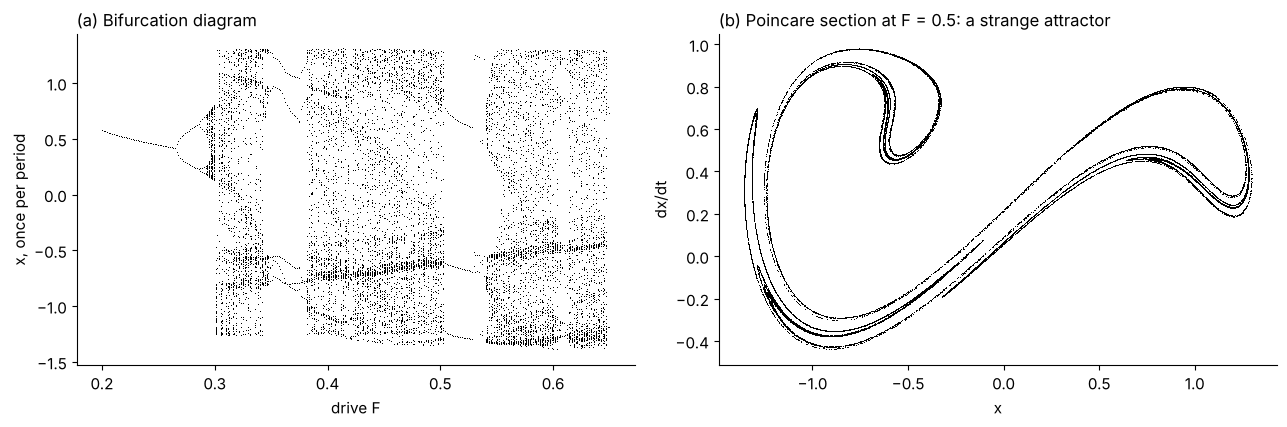

In [12]:
def duffing_strobe(F, x0, v0, gamma=0.3, w=1.2, n_trans=150, n_keep=60, steps=100):
    F, x, v = (np.asarray(z, float).copy() for z in np.broadcast_arrays(F, x0, v0))
    dt = 2*np.pi/w/steps; t = 0.0
    f = lambda t, x, v: (v, -gamma*v + x - x**3 + F*np.cos(w*t))
    keep = []
    for p in range(n_trans + n_keep):
        for _ in range(steps):                                   # RK4, vectorized over all runs
            k1 = f(t, x, v); k2 = f(t + dt/2, x + dt/2*k1[0], v + dt/2*k1[1])
            k3 = f(t + dt/2, x + dt/2*k2[0], v + dt/2*k2[1]); k4 = f(t + dt, x + dt*k3[0], v + dt*k3[1])
            x = x + dt/6*(k1[0] + 2*k2[0] + 2*k3[0] + k4[0]); v = v + dt/6*(k1[1] + 2*k2[1] + 2*k3[1] + k4[1]); t += dt
        if p >= n_trans: keep.append((x.copy(), v.copy()))
    return keep

Fs = np.linspace(0.20, 0.65, 300)
pts = duffing_strobe(Fs, 1.0, 0.0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
for xk, _ in pts: ax[0].plot(Fs, xk, ",", color="k")
ax[0].set_xlabel("drive F"); ax[0].set_ylabel("x, once per period"); ax[0].set_title("(a) Bifurcation diagram")
pts = duffing_strobe(0.5, rng.uniform(-1.5, 1.5, 3000), rng.uniform(-1.5, 1.5, 3000), n_trans=40, n_keep=20)
for xk, vk in pts: ax[1].plot(xk, vk, ",", color="k")
ax[1].set_xlabel("x"); ax[1].set_ylabel("dx/dt"); ax[1].set_title("(b) Poincare section at F = 0.5: a strange attractor")
plt.tight_layout(); plt.show()

**Try it 6.1.** Estimate the largest Lyapunov exponent at $F = 0.5$: follow two runs that start $10^{-8}$ apart, renormalize their distance once per period, and average the log of the growth.

**Breathers: nonlinear waves on the lattice.** Put stiffening shells on the mass-coupled chain of Part 4. Start a short burst of the shortest wave (neighbors out of step) at large amplitude. Without nonlinearity the burst spreads. With it, the burst's frequency rises above the top of the band. Its neighbors cannot carry that frequency, so the energy stays in place: a **discrete breather**, the lattice cousin of an oscillon.

**Course link: Nonlinear Waves.** Near a band edge the slow envelope of such a lattice obeys a discrete nonlinear Schrödinger equation. Bright solitons and breathers appear where nonlinearity pushes the frequency into a gap.

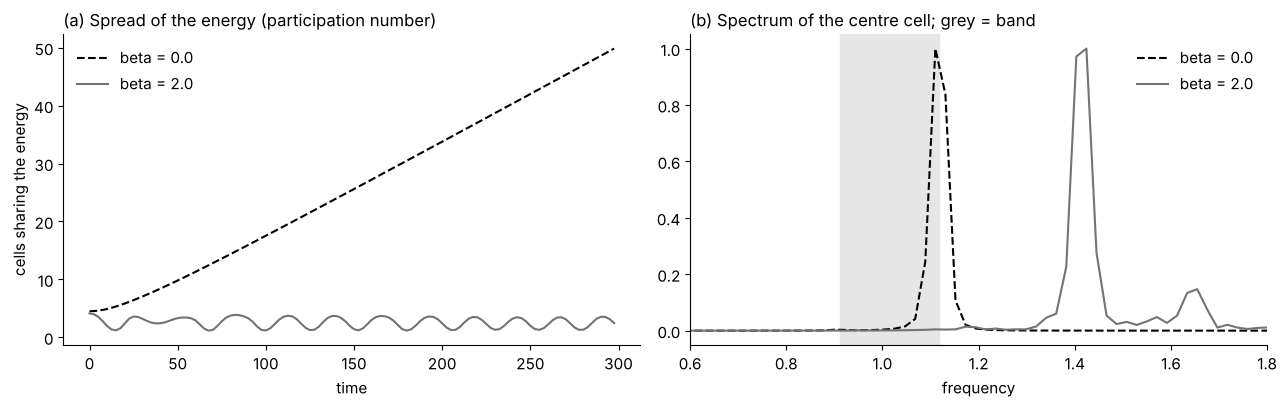

In [13]:
def breather_run(beta, A=0.6, Nc=201, m1=0.0915, dt=0.05, T=300.0):
    M = linalg.circulant(np.r_[m0, m1, np.zeros(Nc - 3), m1]); Minv = np.linalg.inv(M)
    n = np.arange(Nc) - Nc//2
    q = A*(-1.0)**n/np.cosh(n/1.5); v = np.zeros(Nc)
    force = lambda q: -K*q - beta*q**3
    acc = Minv @ force(q); centre, pr, ts = [], [], []
    for s in range(int(T/dt)):
        v += 0.5*dt*acc; q += dt*v; acc = Minv @ force(q); v += 0.5*dt*acc
        centre.append(q[Nc//2])
        if s % 50 == 0:
            e = 0.5*K*q**2 + 0.25*beta*q**4 + 0.5*v*(M @ v)
            pr.append(e.sum()**2/(e**2).sum()); ts.append(s*dt)
    return np.array(ts), np.array(pr), np.array(centre)

top = np.sqrt(K/(m0 - 2*0.0915)); bottom = np.sqrt(K/(m0 + 2*0.0915))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for beta, ls in ((0.0, "--"), (2.0, "-")):
    ts, pr, centre = breather_run(beta)
    ax[0].plot(ts, pr, ls, label=f"beta = {beta}")
    spec = np.abs(np.fft.rfft(centre*np.hanning(len(centre))))
    fr = 2*np.pi*np.fft.rfftfreq(len(centre), 0.05)
    ax[1].plot(fr, spec/spec.max(), ls, label=f"beta = {beta}")
ax[0].set_xlabel("time"); ax[0].set_ylabel("cells sharing the energy"); ax[0].legend(frameon=False)
ax[0].set_title("(a) Spread of the energy (participation number)")
ax[1].axvspan(bottom, top, color="0.9"); ax[1].set_xlim(0.6, 1.8)
ax[1].set_xlabel("frequency"); ax[1].set_title("(b) Spectrum of the centre cell; grey = band"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

With $\beta = 0$ the number of cells that share the energy keeps growing: the burst spreads. With $\beta = 2$ it stays at a few cells, and the centre cell rings above the band (outside the grey strip).

**Try it 6.2.** Lower the amplitude `A`. Find roughly where the breather stops forming. Compare with the amplitude at which $1 + 3\beta A^2/8$ (rescaled to this chain) reaches the band top.

---
## Part 7. Statistics of a vibrating lattice

Maxwell wrote the first statistical law of physics in 1860, a year before the vortex paper: the distribution of molecular speeds in a gas. In two dimensions the speed $s$ of a molecule has density $\propto s\,e^{-s^2/2\sigma^2}$ (a Rayleigh distribution). This part shows the same law appearing in a lattice of vibrating shells.

### 7.1 One cell, many waves: the central limit theorem

A single sine wave, sampled at a random time, has the **arcsine** density $1/(\pi\sqrt{A^2 - x^2})$. A cell in a lattice carries many waves with unrelated phases. Their sum tends to a normal distribution.

**Course link: probability, Nonparametric Statistics.** The Kolmogorov–Smirnov test measures the largest gap between an empirical CDF and a model CDF.

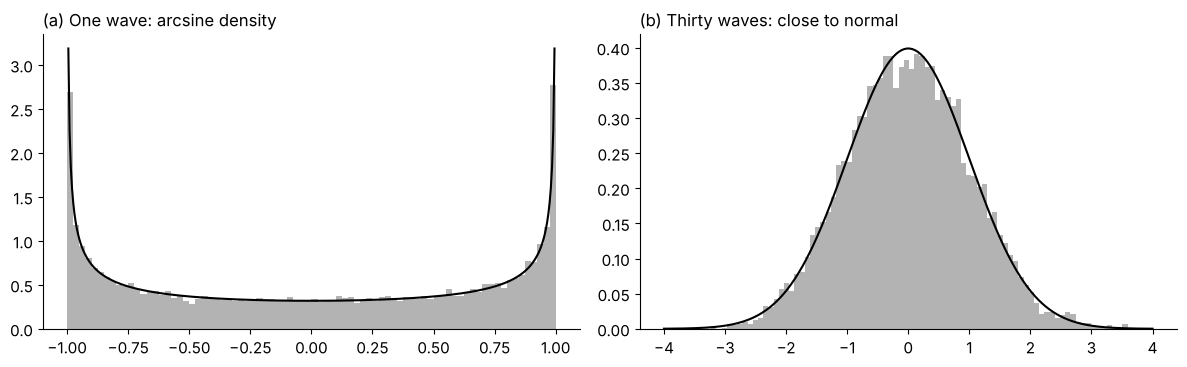

KS test of (b) against N(0,1): statistic 0.0080, p = 0.151


In [14]:
tt = rng.uniform(0, 2*np.pi, 20000)
one = np.cos(tt)
tl = rng.uniform(0, 2000, 20000)
many = sum(np.cos(rng.uniform(0, 2*np.pi) + w*tl) for w in rng.uniform(0.5, 1.5, 30))/np.sqrt(15)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(one, 80, density=True, color="0.7"); xs = np.linspace(-0.995, 0.995, 400)
ax[0].plot(xs, 1/(np.pi*np.sqrt(1 - xs**2))); ax[0].set_title("(a) One wave: arcsine density")
ax[1].hist(many, 80, density=True, color="0.7"); xs = np.linspace(-4, 4, 400)
ax[1].plot(xs, stats.norm.pdf(xs)); ax[1].set_title("(b) Thirty waves: close to normal")
plt.tight_layout(); plt.show()
print("KS test of (b) against N(0,1): statistic %.4f, p = %.3f" % stats.kstest(many, "norm"))

### 7.2 A "thermal" lattice: equipartition and Maxwell's law

Give every normal mode of a lossless chain a random amplitude, as in thermal equilibrium at temperature $k_BT$. The theory is exact here: each displacement is normal with variance $k_BT/K$, whatever the coupling. That is the **equipartition theorem**: each spring holds $\tfrac12 k_BT$ on average.

Each shell has two oval modes, a and b. Its oval size $r = \sqrt{a^2 + b^2}$ then has Maxwell's 2D (Rayleigh) density, and its stored energy $\tfrac{K}{2}r^2$ has the Boltzmann (exponential) density.

The cell below builds the a chain and the b chain of Part 4, draws a thermal state, and evaluates the exact motion at many times.

mean potential energy per oval mode, 40 states:  0.498   (equipartition: kT/2 = 0.5)
same, one state followed in time:              0.439


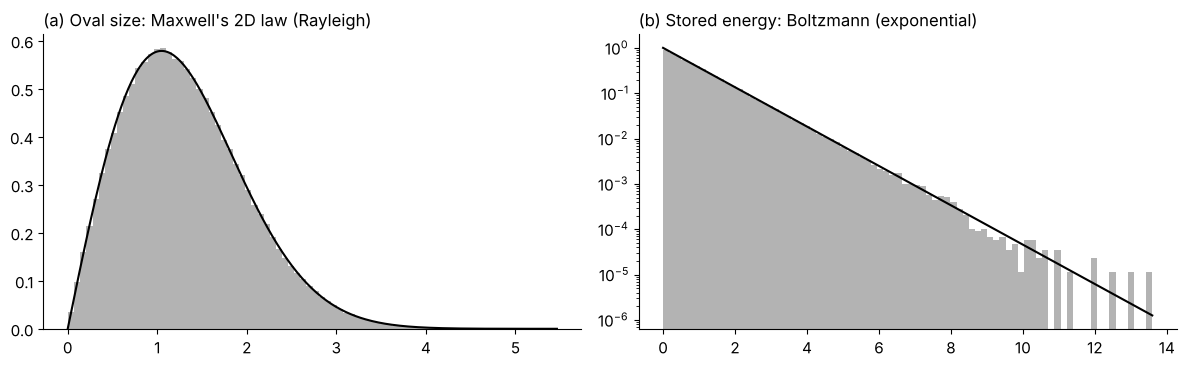

In [15]:
def thermal_chain(m1, Nc=128, kT=1.0, times=np.arange(0, 3000, 1.0), seed=0):
    r = np.random.default_rng(seed)
    M = linalg.circulant(np.r_[m0, m1, np.zeros(Nc - 3), m1])
    w2, Phi = linalg.eigh(K*np.eye(Nc), M)          # Phi^T M Phi = I
    w = np.sqrt(w2)
    A_, B_ = r.normal(0, np.sqrt(kT)/w), r.normal(0, np.sqrt(kT)/w)
    ph = np.outer(w, times)
    q = Phi @ (A_[:, None]*np.cos(ph) + B_[:, None]*np.sin(ph))
    v = Phi @ (w[:, None]*(-A_[:, None]*np.sin(ph) + B_[:, None]*np.cos(ph)))
    return q.T, v.T                                   # [time, cell]

# 40 independent thermal states, each followed for 100 time units
ens = lambda m1, s0: np.vstack([thermal_chain(m1, times=np.arange(0, 100, 1.0), seed=s0 + s_)[0] for s_ in range(40)])
qa, qb = ens(+0.0915, 1000), ens(-0.0915, 2000)
q_one = thermal_chain(+0.0915, seed=7)[0]          # one thermal state, followed for 3000 time units
r = np.sqrt(qa**2 + qb**2).ravel()
U = 0.5*K*r**2
print("mean potential energy per oval mode, 40 states:  %.3f   (equipartition: kT/2 = 0.5)" % (0.5*K*(qa**2).mean()))
print("same, one state followed in time:              %.3f" % (0.5*K*(q_one**2).mean()))

sig_hat = np.sqrt((r**2).mean()/2)                 # Rayleigh MLE
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(r, 80, density=True, color="0.7"); xs = np.linspace(0, r.max(), 300)
ax[0].plot(xs, stats.rayleigh.pdf(xs, scale=sig_hat)); ax[0].set_title("(a) Oval size: Maxwell's 2D law (Rayleigh)")
ax[1].hist(U, 80, density=True, color="0.7"); xs = np.linspace(0, U.max(), 300)
ax[1].plot(xs, stats.expon.pdf(xs, scale=U.mean())); ax[1].set_yscale("log"); ax[1].set_title("(b) Stored energy: Boltzmann (exponential)")
plt.tight_layout(); plt.show()

**Course link: Computational Statistics.** The samples above are **not independent**: neighboring cells and nearby times are correlated. A naive KS test or confidence interval then claims too much. The cell below thins the sample (every 8th cell, every 25th time), finds a bootstrap confidence interval for the Rayleigh scale, and runs a **parametric bootstrap** KS test. That test is needed because the scale was estimated from the same data; the textbook KS p-value assumes a known scale (Lilliefors' point).

In [16]:
rs = np.sqrt(qa[::25, ::8]**2 + qb[::25, ::8]**2).ravel()   # thinned: every 25th snapshot, every 8th cell
mle = lambda x: np.sqrt((x**2).mean()/2)
boot = np.array([mle(rng.choice(rs, rs.size)) for _ in range(2000)])
print(f"n = {rs.size};  scale MLE = {mle(rs):.4f};  95% bootstrap CI = ({np.percentile(boot, 2.5):.4f}, {np.percentile(boot, 97.5):.4f});  theory sqrt(kT/K) = {np.sqrt(1/K):.4f}")

D_obs = stats.kstest(rs, "rayleigh", args=(0, mle(rs))).statistic
D_sim = []
for _ in range(1000):
    xs = stats.rayleigh.rvs(scale=mle(rs), size=rs.size, random_state=rng)
    D_sim.append(stats.kstest(xs, "rayleigh", args=(0, mle(xs))).statistic)
print(f"KS statistic {D_obs:.4f};  parametric-bootstrap p = {np.mean(np.array(D_sim) >= D_obs):.3f}")

n = 2560;  scale MLE = 1.0468;  95% bootstrap CI = (1.0272, 1.0669);  theory sqrt(kT/K) = 1.0477


KS statistic 0.0118;  parametric-bootstrap p = 0.728


**Try it 7.1.** The printout above compares 40 thermal states with one state followed for a long time. The single state misses $k_BT/2$ by a clear margin. In a linear lattice each mode keeps the energy it started with, so a long time average cannot correct an unlucky start. Time averages and ensemble averages agree only when the motion mixes energy between modes (**ergodicity**). Repeat the bootstrap with `q_one` in place of `qa`: the interval comes out narrow and in the wrong place. Explain why the bootstrap cannot see this error. Section 7.4 shows what nonlinearity changes.

### 7.3 Statistical learning: principal components find the modes

Stack many independent snapshots of the shell velocities into a data matrix and run principal component analysis (PCA). The covariance of the velocities is exactly $k_BT\,M^{-1}$. Its eigenvectors are the lattice modes $e^{ikn}$, and its eigenvalues are $k_BT/(m_0 + 2m_1\cos k)$. PCA recovers the band structure from data alone. (The displacements would show nothing: their covariance is $k_BT/K$ times the identity, because the springs are local and only the mass couples cells.)

**Course link: Statistical Learning, Numerical Matrix Analysis.** PCA is the SVD of the centered data matrix. In fluid mechanics it is called proper orthogonal decomposition (POD).

**Try it 7.2a.** Cut the number of snapshots to 500. The sorted variances spread far beyond the theory curve. Compare the spread with the Marchenko–Pastur law for a random covariance matrix with $n/p = 500/128$. Pairs of modes at $\pm k$ share a variance, so PCA cannot split them: any mix of the cosine and the sine is an equally good component.

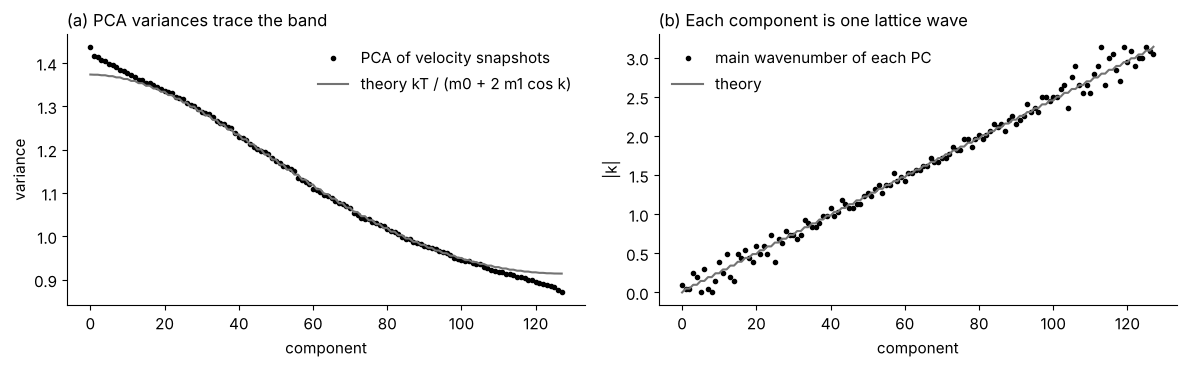

In [17]:
# 50,000 independent thermal snapshots of the b chain (each a fresh draw of every mode)
Nc = 128
Mb = linalg.circulant(np.r_[m0, -0.0915, np.zeros(Nc - 3), -0.0915])
w2, Phi = linalg.eigh(K*np.eye(Nc), Mb)
X = (Phi @ rng.normal(0, 1.0, (Nc, 50000))).T      # velocities: each mode gets variance kT = 1
X = X - X.mean(0)
U_, S_, Vt = np.linalg.svd(X, full_matrices=False)
lam = S_**2/(X.shape[0] - 1)
k_lat = 2*np.pi*np.fft.fftfreq(X.shape[1])
lam_th = np.sort(1.0/(m0 + 2*(-0.0915)*np.cos(k_lat)))[::-1]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(lam, ".", label="PCA of velocity snapshots"); ax[0].plot(lam_th, label="theory kT / (m0 + 2 m1 cos k)")
ax[0].set_xlabel("component"); ax[0].set_ylabel("variance"); ax[0].legend(frameon=False); ax[0].set_title("(a) PCA variances trace the band")
k_pc = np.abs(k_lat[np.argmax(np.abs(np.fft.fft(Vt, axis=1)), axis=1)])     # main wavenumber of each component
k_th = np.sort(np.abs(k_lat))                                              # theory: long waves first (largest variance)
ax[1].plot(k_pc, ".", label="main wavenumber of each PC"); ax[1].plot(k_th, label="theory")
ax[1].set_xlabel("component"); ax[1].set_ylabel("|k|"); ax[1].legend(frameon=False); ax[1].set_title("(b) Each component is one lattice wave")
plt.tight_layout(); plt.show()

### 7.4 Fermi–Pasta–Ulam–Tsingou: when does a lattice reach equilibrium?

In a linear lattice each mode keeps its energy forever. So a lattice that starts with all its energy in one mode never reaches the thermal state of 7.2. Fermi, Pasta, Ulam and Tsingou (1955) added a small nonlinearity and expected the energy to spread evenly. Instead it came back to the first mode, almost completely. Zabusky and Kruskal (1965) explained the return with solitons of the KdV equation, and named the soliton in doing so.

The run below uses their chain of 32 masses with a quadratic (α) force. Then a stronger quartic (β) force at higher energy spreads the energy over all modes. The **normalized spectral entropy** $S = -\sum p_k\ln p_k/\ln N$, with $p_k$ the share of energy in mode $k$, measures the spread: 0 for one mode, 1 for equal shares.

**Course link: Nonlinear Waves, Discrete Dynamical Systems, probability.**

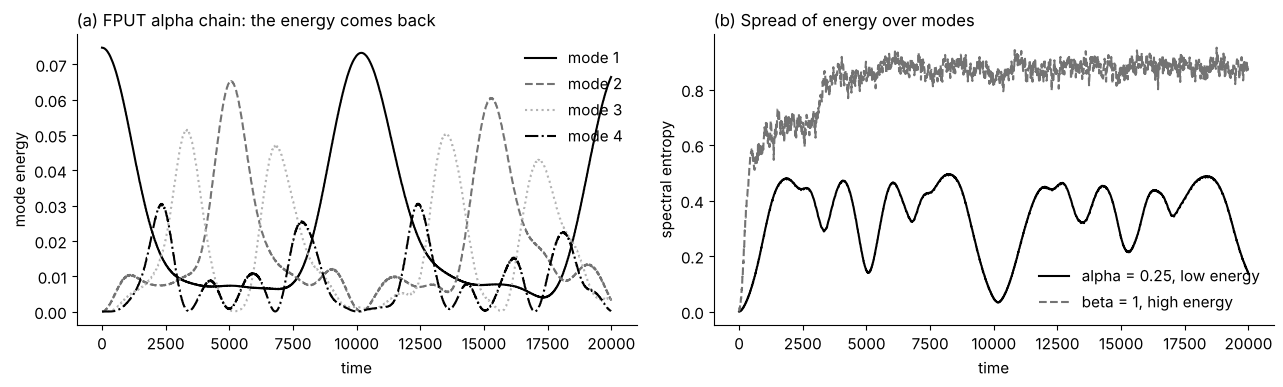

return of mode 1 at t = 10180: 98.0% of its starting energy


In [18]:
def fput(N=32, alpha=0.0, beta=0.0, A=1.0, T=20000.0, dt=0.1, every=100):
    n = np.arange(1, N + 1); kk = np.arange(1, N + 1)
    phi = np.sqrt(2/(N + 1))*np.sin(np.outer(kk, n)*np.pi/(N + 1)); w = 2*np.sin(kk*np.pi/(2*(N + 1)))
    x = A*np.sin(n*np.pi/(N + 1)); v = np.zeros(N)
    def force(x):
        d = np.diff(np.r_[0, x, 0]); f = d + alpha*d**2 + beta*d**3
        return f[1:] - f[:-1]
    a = force(x); E = []
    for s in range(int(T/dt)):
        v += 0.5*dt*a; x += dt*v; a = force(x); v += 0.5*dt*a
        if s % every == 0:
            Q, P = phi @ x, phi @ v; E.append(0.5*(P**2 + (w*Q)**2))
    return np.arange(len(E))*every*dt, np.array(E)

def spectral_entropy(E):
    p = E/E.sum(1, keepdims=True)
    return -(p*np.log(p + 1e-300)).sum(1)/np.log(E.shape[1])

t1, E1 = fput(alpha=0.25, A=1.0)
t2, E2 = fput(beta=1.0, A=6.0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for m, ls in zip(range(4), ["-", "--", ":", "-."]): ax[0].plot(t1, E1[:, m], ls, label=f"mode {m+1}")
ax[0].set_xlabel("time"); ax[0].set_ylabel("mode energy"); ax[0].legend(frameon=False); ax[0].set_title("(a) FPUT alpha chain: the energy comes back")
ax[1].plot(t1, spectral_entropy(E1), label="alpha = 0.25, low energy")
ax[1].plot(t2, spectral_entropy(E2), "--", label="beta = 1, high energy")
ax[1].set_xlabel("time"); ax[1].set_ylabel("spectral entropy"); ax[1].legend(frameon=False); ax[1].set_title("(b) Spread of energy over modes")
plt.tight_layout(); plt.show()
i = np.argmax(E1[100:, 0]) + 100
print(f"return of mode 1 at t = {t1[i]:.0f}: {E1[i, 0]/E1[0, 0]:.1%} of its starting energy")

**Try it 7.2b.** For the β chain, collect $p_k$ over the last half of the run. Compare the distribution of each mode's energy over time with the exponential law of 7.2. Is the nonlinear chain "thermal"?

**Try it 7.3.** Put a weak cubic term into the shell chain of Part 6 and start it in one long mode. Does the shell lattice behave like FPUT (return) or like a gas (spread)?

---
## Part 8. Where this leads

- **Solitons and oscillons.** Part 6 gives the ingredients: dispersion from the lattice, nonlinearity from the shells. Breathers in the band gaps of experiments 12 and 13 are oscillons on a lattice. Granular crystals (Hertz contacts) give strongly nonlinear solitary waves without any added term.
- **A classical superfluid.** For weak nonlinearity the slow envelope of the lattice obeys a discrete Gross–Pitaevskii (nonlinear Schrödinger) equation. With a stiffening shell, a uniform vibration at the band edge can flow past an obstacle without a wake below a critical speed, and shed quantized vortices above it. The phase of each cell's vibration plays the superfluid order parameter.
- **Maxwell's vortex lattice, again.** A rotating superfluid forms a regular array of identical vortices, each carrying one quantum of circulation. It is the closest real system to Maxwell's 1861 picture.

### Reading list

- J. C. Maxwell, *On Physical Lines of Force*, Philosophical Magazine, 1861–62, Parts I–IV.
- J. C. Maxwell, *Illustrations of the Dynamical Theory of Gases*, Philosophical Magazine, 1860.
- D. M. Siegel, *Innovation in Maxwell's Electromagnetic Theory: Molecular Vortices, Displacement Current, and Light*, Cambridge University Press, 1991.
- H. Lamb, *Hydrodynamics*, chapters on potential flow and added mass.
- L. Brillouin, *Wave Propagation in Periodic Structures*, 1946.
- A. Taflove and S. C. Hagness, *Computational Electrodynamics: The Finite-Difference Time-Domain Method*.
- S. H. Strogatz, *Nonlinear Dynamics and Chaos*.
- G. B. Whitham, *Linear and Nonlinear Waves*.
- S. Flach and A. V. Gorbach, "Discrete breathers: advances in theory and applications", Physics Reports, 2008.
- G. Gallavotti (ed.), *The Fermi–Pasta–Ulam Problem: A Status Report*, Springer, 2008.
- V. F. Nesterenko, *Dynamics of Heterogeneous Materials*, Springer, 2001.
- I. Carusotto and C. Ciuti, "Quantum fluids of light", Reviews of Modern Physics, 2013.
- B. Efron and R. J. Tibshirani, *An Introduction to the Bootstrap*.
- L. Wasserman, *All of Nonparametric Statistics*.